# M3 experiments: controlled post-image corruption study on Nepal
Run order: inventory → m3_build_verify → train_m3 → **corruption** → analysis

Run on: Colab **L4 GPU**. Expected 1.5-2.5 h (measured in section 8 before the full run), about 8-12 compute units
(estimate). Resumable: finished (checkpoint, condition) files are skipped.

**Order and gates**
1-4. Setup, pinned code, Nepal data (tier3 only)
5. The 16 checkpoints: 15 primary (M0, M1 CE, M1 Dice+focal, M2, M3; seeds 0-2) + 1 EXPLORATORY ablation; SHA-256
   checked against the inventory notebook's table and the training notebook's verification files
6. Input identity: every clean crop vs the repo's original loading path, Nepal source files unchanged since before 18 Nov,
   exact GPU-vs-CPU confusion counting
7. Condition and crop manifests
8. **Pipeline timing** on 64 crops (clean and the slowest corruption): data loading, GPU inference, CPU scoring
9. **Clean condition**, all 16 checkpoints
10. **Clean reproduction gate**: the 12 existing checkpoints vs `eval_extras/nepal_final/cmp_*_test.npz` (read only).
    If any fails, the notebook stops here and nothing corrupted is run.
11. The 9 corrupted conditions (only after the gate), with input-hash determinism checks
12. Example images; 13-14. analysis, tables and figures (EXPLORATORY ablation always separate); 15. timing, compute, summary

**Status of the evaluations (carried into every table)**
- M0, M1 CE, M1 Dice+focal, M2: the frozen 18 Nov Nepal comparison set. Their clean pass here is a reproduction.
- M3: designed and trained on 20 Nov, AFTER the 18 Nov Nepal results were known; every M3 choice was made on Florence
  only. This is M3's first Nepal evaluation but it is a **post-hoc evaluation, not a blind test**.
- Two-head ablation: **EXPLORATORY**, one seed, post-hoc; never part of the primary comparison or any significance claim.

Writes only inside `m3_experiments/`.

## 1. Setup

In [ ]:
# GPU check, Drive mount and project paths
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
import os, sys, json, time, hashlib, datetime, platform, shutil, math, subprocess, gc, random
from google.colab import drive
drive.mount("/content/drive")
D = "/content/drive/MyDrive/MAAI 902 X 901 PROJECT"
CK, EXTRAS, NEPAL = f"{D}/checkpoints", f"{D}/eval_extras", f"{D}/eval_extras/nepal_final"
EXP = f"{D}/m3_experiments"
X, MAN = "/content/xbd", "/content/xbd/rscc_flood_manifest.csv"
REPO, REPO_COMMIT, CODE = "/content/FloodVerify", "8f10e61", "/content/m3code"
# The earlier notebooks must have run first (the M3 checkpoints exist)
assert os.path.isdir(f"{EXP}/m3/checkpoints"), "run Stages 2-4 first"
# out(): every path this notebook writes to is built here; anything outside m3_experiments/ raises
_EXP_REAL = os.path.realpath(EXP)
def out(*parts):
    p = os.path.realpath(os.path.join(EXP, *parts))
    if not (p == _EXP_REAL or p.startswith(_EXP_REAL + os.sep)):
        raise ValueError(f"refusing to write outside m3_experiments: {p}")
    return p
# Write JSON, converting numpy values to plain Python numbers
def jdump(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
# Size and modification time of every existing project file (read only)
def snapshot():
    snap = {}
    for name in sorted(os.listdir(D)):
        if name != "m3_experiments":
            snap[f"[top] {name}"] = os.path.getmtime(f"{D}/{name}")
    for root in (CK, EXTRAS, f"{D}/figures"):
        for dp, _, fs in os.walk(root):
            for fn in fs:
                st = os.stat(os.path.join(dp, fn)); snap[os.path.relpath(os.path.join(dp, fn), D)] = [st.st_size, st.st_mtime]
    return snap
# Snapshot before any work, session start time and GPU name
BEFORE = snapshot()
SESSION = {"session_start": datetime.datetime.now().isoformat(timespec="seconds"),
           "gpu": subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()}
# Output folders for this notebook
for s in ["corruption/manifest", "corruption/input_hashes", "corruption/samples", "corruption/predictions",
          "corruption/predictions_EXPLORATORY_ablation", "corruption/timing", "results", "figures", "logs"]:
    os.makedirs(out(s), exist_ok=True)
print(SESSION)

name, memory.total [MiB], driver_version
NVIDIA L4, 23034 MiB, 580.82.07
Mounted at /content/drive
{'session_start': '2026-11-20T21:54:02', 'gpu': 'NVIDIA L4'}


## 2. Repository pinned to `main@8f10e61`

In [ ]:
# Fresh clone of the repository, pinned to commit 8f10e61 and installed in editable mode (not modified)
%cd /content
!rm -rf /content/FloodVerify
!git clone -q https://github.com/aaarrvind/FloodVerify.git /content/FloodVerify
%cd /content/FloodVerify
!git checkout -q 8f10e61 && git log -1 --format='%h %cd %s'
!pip install -q -e . --no-deps jsonschema
%cd /content
# Make the repo and the new M3 code folder importable
sys.path.insert(0, "/content/FloodVerify/src")

/content
/content/FloodVerify
8f10e61 Fri Nov 20 14:07:06 2026 +0400 Merge pull request #28 from aaarrvind/m5/generate-advisory
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for floodsitrep (pyproject.toml) ... done
/content


## 3. Code: earlier modules from `m3_experiments/code/` (SHA-256 checked) plus the three corruption modules
The first cell copies the six earlier files back to the Colab disk and checks each against `code/MANIFEST.json`. The
next three cells write the corruption code; the code in those cells is exactly the code that ran.

In [ ]:
# Copy the earlier code back to the Colab disk and check it against MANIFEST.json
os.makedirs(CODE, exist_ok=True); sys.path.insert(0, CODE)
def sha(p): return hashlib.sha256(open(p, "rb").read()).hexdigest()
MANI = json.load(open(out("code", "MANIFEST.json")))
for fn in ("m3_model.py", "m3_register.py", "train_m3.py", "m3_tests.py", "metrics_ext.py", "m3_analysis.py"):
    shutil.copy(out("code", fn), f"{CODE}/{fn}")
    assert sha(f"{CODE}/{fn}") == MANI["files"][fn], f"{fn} differs from its recorded version"
print("earlier code verified")

earlier code verified


### `corruption.py`: the corruptions
Deterministic corruptions of the post image only, applied to the 8-bit RGB crop before normalisation (numpy, scipy and
Pillow; no torch). The pre image, the labels and the valid mask are never changed, and pixels that are black no-data in
the clean post image are set back to black afterwards, so only image content is degraded.

| Condition | Severity 1 / 2 / 3 |
| --- | --- |
| Gaussian noise, sigma in 0-255 units (rounded, clipped) | 10 / 25 / 50 |
| Gaussian blur, sigma in px (reflect border, truncated at 3 sigma, per channel) | 1 / 2 / 4 |
| JPEG re-encoding, quality (Pillow, 4:2:0 chroma subsampling) | 50 / 25 / 10 |

`crop_seed` gives each crop and condition its own noise seed (from an MD5 hash of a fixed salt, the crop id and the
condition), so a crop always gets the same noise whatever the session, worker or batch order. `corrupt` applies a
condition, `sha256` hashes an image array, and `conditions_table` lists the conditions.

In [ ]:
%%writefile /content/m3code/corruption.py
"""Deterministic post-image corruptions (corruption study v1). numpy, scipy and pillow only; no torch.

Applied to the POST crop only, as uint8 RGB [512, 512, 3], before ImageNet normalisation. The pre crop,
the labels and the valid (no-data) mask are taken from the clean images and never changed. Pixels that
are no-data (pure black) in the clean post crop are set back to black after corrupting, so the no-data
fill the models were trained with stays as it was; only image content is degraded.

Conditions (fixed; severities 1-3):
    clean
    gnoise_s1/2/3   additive Gaussian noise, sigma 10 / 25 / 50 (in 0-255 units), rounded, clipped
    gblur_s1/2/3    Gaussian blur, sigma 1 / 2 / 4 px (about 0.5 / 1 / 2 m at 0.5 m GSD), reflect border,
                    kernel truncated at 3 sigma, per channel, rounded
    jpeg_s1/2/3     JPEG re-encoding with Pillow, quality 50 / 25 / 10, 4:2:0 chroma subsampling
Noise seed: first 16 hex digits of md5("<SALT>|<crop id>|<condition>") -> numpy default_rng. The same crop
and condition always get the same noise, whatever the model, batch order, worker or session.
"""
import hashlib
import io

import numpy as np

SALT = "m3_experiments/corruption_v1"
CONDITIONS = {   # id: (type, severity, parameter, unit)
    "clean": ("clean", 0, None, None),
    "gnoise_s1": ("gaussian_noise", 1, 10.0, "sigma, 0-255 units"),
    "gnoise_s2": ("gaussian_noise", 2, 25.0, "sigma, 0-255 units"),
    "gnoise_s3": ("gaussian_noise", 3, 50.0, "sigma, 0-255 units"),
    "gblur_s1": ("gaussian_blur", 1, 1.0, "sigma, pixels"),
    "gblur_s2": ("gaussian_blur", 2, 2.0, "sigma, pixels"),
    "gblur_s3": ("gaussian_blur", 3, 4.0, "sigma, pixels"),
    "jpeg_s1": ("jpeg", 1, 50, "quality"),
    "jpeg_s2": ("jpeg", 2, 25, "quality"),
    "jpeg_s3": ("jpeg", 3, 10, "quality"),
}


def crop_seed(crop_id, condition):
    return int(hashlib.md5(f"{SALT}|{crop_id}|{condition}".encode()).hexdigest()[:16], 16)


def corrupt(post, condition, crop_id):
    """uint8 [H, W, 3] post crop -> corrupted uint8 [H, W, 3] (a new array; the input is not modified)."""
    kind, _, param, _ = CONDITIONS[condition]
    x = np.ascontiguousarray(post)
    if x.dtype != np.uint8 or x.ndim != 3 or x.shape[2] != 3:
        raise ValueError(f"expected uint8 HxWx3, got {x.dtype} {x.shape}")
    if kind == "clean":
        return x.copy()
    if kind == "gaussian_noise":
        rng = np.random.default_rng(crop_seed(crop_id, condition))
        y = np.clip(np.rint(x.astype(np.float64) + rng.normal(0.0, param, size=x.shape)), 0, 255).astype(np.uint8)
    elif kind == "gaussian_blur":
        from scipy.ndimage import gaussian_filter

        y = gaussian_filter(x.astype(np.float64), sigma=(param, param, 0), mode="reflect", truncate=3.0)
        y = np.clip(np.rint(y), 0, 255).astype(np.uint8)
    elif kind == "jpeg":
        from PIL import Image

        buf = io.BytesIO()
        Image.fromarray(x, "RGB").save(buf, format="JPEG", quality=int(param), subsampling=2, optimize=False)
        y = np.array(Image.open(io.BytesIO(buf.getvalue())).convert("RGB"))
    else:
        raise ValueError(kind)
    y[x.sum(axis=2) == 0] = 0          # keep clean no-data fill as it was
    return y


def sha256(a):
    return hashlib.sha256(np.ascontiguousarray(a).tobytes()).hexdigest()


def conditions_table():
    import platform

    import PIL
    import scipy

    return [{"condition": c, "type": t, "severity": s, "parameter": p, "unit": u,
             "seed_rule": ("md5(SALT|crop_id|condition)[:16] -> numpy.random.default_rng" if t == "gaussian_noise" else "deterministic"),
             "salt": SALT, "numpy": np.__version__, "scipy": scipy.__version__, "pillow": PIL.__version__,
             "python": platform.python_version()}
            for c, (t, s, p, u) in CONDITIONS.items()]

Writing /content/m3code/corruption.py


### `corruption_eval.py`: the evaluation engine
- `CorruptedTiles`: the repo's Nepal dataset (sorted, no augmentation) with the post crop corrupted.
- `run_condition`: one pass per condition. Each crop is loaded and corrupted once, and the same batch goes to every
  checkpoint, so all models see byte-identical inputs; the SHA-256 of every corrupted post crop is returned. Per
  checkpoint it produces the same outputs as the repo's `building_level.run` (sorted crops, batch 8, mixed precision,
  argmax): per-crop pixel confusion matrices and per-image building results.
- `gpu_confusions`: counts the confusion matrices on the GPU; checked for exact equality with the repo's CPU code.
- `_score_image_all`: building-level scoring of one stitched image, run in a pool of CPU processes alongside GPU
  inference.
- Time spent in each step (waiting for data, GPU, stitching, scoring) is recorded per condition.

In [ ]:
%%writefile /content/m3code/corruption_eval.py
"""Corruption-study evaluation engine (needs torch and floodsitrep).

One pass per condition: each Nepal crop is loaded and corrupted ONCE, and that same tensor batch is fed to
every checkpoint, so all models see byte-identical inputs (the SHA-256 of every corrupted post crop is
logged). Per checkpoint the outputs are exactly those of ``building_level.run`` (same sorted crop order,
batch size 8, AMP autocast, argmax): per-crop 5x5 pixel confusions, and per 1024 px image the
building-level matrix, component and false-component counts. Building scoring runs in a process pool
alongside GPU inference.

Timing (seconds, recorded per condition): data_wait (main thread blocked on the DataLoader), gpu
(forward + argmax + confusion on GPU, bracketed by cuda.synchronize, per model), stitch (CPU),
score_backpressure (main thread blocked because the scoring pool was full), score_tail (waiting for
the pool after the last batch), score_worker_cpu (sum of time spent inside the scoring workers), wall.
"""
import hashlib
import os
import time
from concurrent.futures import ProcessPoolExecutor
from multiprocessing import get_context

import numpy as np
import torch
from torch.utils.data import DataLoader

from corruption import CONDITIONS, corrupt
from floodsitrep.data.dataset import XbdTiles, _to_tensor
from floodsitrep.data.tiling import PART_ORIGIN, load_crop, source_paths, tile_name


class CorruptedTiles(XbdTiles):
    """XbdTiles (no augmentation, sorted as building_level.run) with the post crop corrupted."""

    def __init__(self, xbd_root, manifest, condition, role="test", limit=0):
        super().__init__(xbd_root, manifest, role=role, augment=False)
        self.rows = sorted(self.rows, key=lambda r: (r["event"], r["tile_id"], r["part"]))
        if limit:
            self.rows = self.rows[:limit]
        if condition not in CONDITIONS:
            raise ValueError(condition)
        self.condition = condition

    def __getitem__(self, i):
        r = self.rows[i]
        tid = tile_name(r)
        pre, post, mask, valid = load_crop(self.root, r)          # valid from the CLEAN images
        post_c = corrupt(post, self.condition, tid)
        return {"pre": _to_tensor(pre), "post": _to_tensor(post_c),
                "mask": torch.from_numpy(np.ascontiguousarray(mask).astype(np.int64)),
                "valid": torch.from_numpy(np.ascontiguousarray(valid)), "tile_id": tid,
                "post_sha256": hashlib.sha256(post_c.tobytes()).hexdigest(),
                "pre_sha256": hashlib.sha256(np.ascontiguousarray(pre).tobytes()).hexdigest(),
                "valid_px": int(valid.sum()),
                "building_px": int(((mask >= 1) & (mask <= 4) & valid).sum())}


def gpu_confusions(pred, mask, valid, n=5):
    """[N,H,W] prediction, target, valid on the GPU -> [N,5,5] int64, identical to metrics.confusion per crop."""
    N = pred.shape[0]
    keep = valid & (mask >= 0) & (mask < n)
    idx = (torch.arange(N, device=pred.device).view(N, 1, 1) * n * n + mask.clamp(0, n - 1) * n + pred)[keep]
    return torch.bincount(idx, minlength=N * n * n).view(N, n, n)


def _score_image_all(preds, valid, label_path, detect_share=0.5, min_px=10):
    """Process-pool worker: building-level scoring of one stitched image for every model."""
    from floodsitrep.cv.eval.building_level import label_buildings, rasterise, score_image

    t0 = time.perf_counter()
    blds = label_buildings(label_path)
    inst = rasterise(blds, preds.shape[-1])
    out = [score_image(preds[k], valid, blds, inst=inst, detect_share=detect_share, min_px=min_px)
           for k in range(preds.shape[0])]
    return out, time.perf_counter() - t0


@torch.no_grad()
def run_condition(models, condition, xbd_root, manifest, out_paths=None, batch_size=8, num_workers=6,
                  score_workers=4, max_pending=8, limit=0, device="cuda", amp=True, verify_cpu_every=0):
    """models: {run_name: model (eval mode, on device)}. out_paths: {run_name: npz path} or None.

    verify_cpu_every: 0 = off; 1 = every crop; n = every n-th crop (by position): the GPU confusion matrix of
    every model on that crop is compared for EXACT equality with the repo's metrics.confusion on the CPU.
    Returns (results per run, hash rows, crop info rows, timing dict).
    """
    from floodsitrep.cv.eval import metrics as M

    names = list(models)
    dev = torch.device(device)
    ds = CorruptedTiles(xbd_root, manifest, condition, limit=limit)
    rows = {tile_name(r): r for r in ds.rows}
    dl = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    K = len(names)
    crop_ids, crop_cms = [], {n: [] for n in names}
    hashes, crops = [], []
    img_ids, pending, finished = [], [], []
    st = {"base": None}
    t = {"data_wait": 0.0, "gpu": 0.0, "stitch": 0.0, "score_backpressure": 0.0, "score_tail": 0.0,
         "score_worker_cpu": 0.0, "verify": 0.0, "cpu_confusion_checked": 0, "cpu_confusion_mismatches": 0,
         "gpu_per_model": {n: 0.0 for n in names}}
    pool = ProcessPoolExecutor(max_workers=score_workers, mp_context=get_context("fork")) if score_workers else None

    class _Done:                                   # score_workers=0: score in the main process (fallback)
        def __init__(self, v):
            self.v = v

        def result(self):
            return self.v

    def drain(block_until):
        while len(pending) > block_until:
            base, fut = pending.pop(0)
            res, secs = fut.result()
            t["score_worker_cpu"] += secs
            finished.append((base, res))

    def flush():
        if st["base"] is None:
            return
        tb = time.perf_counter()
        drain(max_pending - 1)
        t["score_backpressure"] += time.perf_counter() - tb
        label = source_paths(xbd_root, st["row"])["label"]
        fut = (pool.submit(_score_image_all, st["pred"], st["valid"], label) if pool
               else _Done(_score_image_all(st["pred"], st["valid"], label)))
        pending.append((st["base"], fut))
        img_ids.append(st["base"])

    if pool:   # start every scoring process now, before the DataLoader starts its threads (fork safety)
        for f in [pool.submit(time.sleep, 0.2) for _ in range(score_workers)]:
            f.result()
    t_wall = time.perf_counter()
    try:
        it = iter(dl)
        while True:
            tw = time.perf_counter()
            try:
                b = next(it)
            except StopIteration:
                break
            t["data_wait"] += time.perf_counter() - tw
            pre = b["pre"].to(dev, non_blocking=True)
            post = b["post"].to(dev, non_blocking=True)
            mask = b["mask"].to(dev, non_blocking=True)
            valid = b["valid"].to(dev, non_blocking=True)
            preds = []
            for n in names:
                torch.cuda.synchronize(dev)
                tg = time.perf_counter()
                with torch.autocast(dev.type, enabled=amp and dev.type == "cuda"):
                    p = models[n](pre, post).argmax(1)
                crop_cms[n].append(gpu_confusions(p, mask, valid).cpu().numpy())
                preds.append(p.to(torch.uint8))
                torch.cuda.synchronize(dev)
                dt = time.perf_counter() - tg
                t["gpu"] += dt
                t["gpu_per_model"][n] += dt
            P = torch.stack(preds, 1).cpu().numpy()                    # [N, K, H, W] uint8
            if verify_cpu_every:
                tv = time.perf_counter()
                masks_np, valids_np = b["mask"].numpy(), b["valid"].numpy()
                for i in range(P.shape[0]):
                    if (len(crop_ids) + i) % verify_cpu_every == 0:
                        for k, n in enumerate(names):
                            t["cpu_confusion_checked"] += 1
                            if not np.array_equal(crop_cms[n][-1][i], M.confusion(P[i, k], masks_np[i], valids_np[i])):
                                t["cpu_confusion_mismatches"] += 1
                t["verify"] += time.perf_counter() - tv
            ts = time.perf_counter()
            valids = b["valid"].numpy()
            for i, tid in enumerate(b["tile_id"]):
                crop_ids.append(tid)
                hashes.append({"crop_id": tid, "condition": condition, "post_sha256": b["post_sha256"][i],
                               "pre_sha256": b["pre_sha256"][i]})
                crops.append({"crop_id": tid, "valid_px": int(b["valid_px"][i]), "building_px": int(b["building_px"][i])})
                row = rows[tid]
                base = tid.rsplit("_p", 1)[0]
                if base != st["base"]:
                    flush()
                    st.update(base=base, row=row, pred=np.zeros((K, 1024, 1024), np.uint8),
                              valid=np.zeros((1024, 1024), bool))
                x0, y0 = PART_ORIGIN[row["part"]]
                st["pred"][:, y0:y0 + 512, x0:x0 + 512] = P[i]
                st["valid"][y0:y0 + 512, x0:x0 + 512] = valids[i]
            t["stitch"] += time.perf_counter() - ts
        flush()
        tt = time.perf_counter()
        drain(0)
        t["score_tail"] = time.perf_counter() - tt
    finally:
        if pool:
            pool.shutdown(wait=True)
    t["wall"] = time.perf_counter() - t_wall
    t.update({"crops": len(crop_ids), "images": len(img_ids), "models": K})
    assert [b for b, _ in finished] == img_ids
    results = {}
    for k, n in enumerate(names):
        res = {"crop_ids": np.array(crop_ids), "crop_cms": np.concatenate(crop_cms[n]).astype(np.int64),
               "img_ids": np.array(img_ids),
               "bcms": np.stack([r[k][0] for _, r in finished]), "comps": np.array([r[k][1] for _, r in finished]),
               "falses": np.array([r[k][2] for _, r in finished]), "skipped": np.array([r[k][3] for _, r in finished]),
               "condition": np.array(condition), "run": np.array(n)}
        results[n] = res
        if out_paths and n in out_paths:
            os.makedirs(os.path.dirname(out_paths[n]), exist_ok=True)
            np.savez_compressed(out_paths[n], **res)
    return results, hashes, crops, t

Writing /content/m3code/corruption_eval.py


### `corruption_analysis.py`: metrics and statistics
- `image_level` and `metrics_on`: per-image confusion data, and every pixel and building metric on any set of images.
- `paired_delta_bootstrap`: degradation of each metric from the checkpoint's own clean pass (absolute and relative),
  with 95% intervals from 1,000 resamples of the 619 Nepal images (the 4 crops of an image stay together). For a family,
  the same image resample is used for all 3 seeds.
- `reproduction_check`: compares a fresh clean pass with the saved Nepal result of the same checkpoint, against the
  agreed tolerances.

In [ ]:
%%writefile /content/m3code/corruption_analysis.py
"""Corruption-study analysis (numpy; uses the repo's metrics and building summaries, no torch).

Baseline = each checkpoint's OWN clean Nepal pass from the same session. Degradation of a metric m:
    absolute  delta = m(condition) - m(clean)
    relative  delta_rel = delta / m(clean)
Paired bootstrap over IMAGES (619 Nepal images; the 4 crops of an image stay together): each resample
draws images with replacement, recomputes m(clean) and m(condition) on the SAME images, and keeps the
difference. For a family (3 seeds) the same image resample is used for every seed and the seed-mean of
the deltas is kept, so the interval reflects image sampling; the spread across seeds is reported
separately as the std over seeds.
"""
import numpy as np

from floodsitrep.cv.eval.building_level import summarise_buildings
from metrics_ext import extended

PIXEL_KEYS = ["xview2_pixel_score", "loc_f1", "damage_macro_f1", "damage_f1_hm", "building_iou", "binary_miou",
              "miou", "dmg_f1_no_damage", "dmg_f1_minor", "dmg_f1_major", "dmg_f1_destroyed"]
BUILDING_KEYS = ["xview2_building_score", "loc_recall", "loc_precision"]
BOOT_KEYS = ["xview2_pixel_score", "damage_macro_f1", "building_iou", "miou", "loc_f1", "dmg_f1_destroyed",
             "xview2_building_score"]


def image_level(z):
    """npz dict -> per-image arrays aligned with z['img_ids']: pixel cms [I,5,5], bcms [I,4,5], comps, falses."""
    img_ids = [str(x) for x in z["img_ids"]]
    pos = {b: i for i, b in enumerate(img_ids)}
    cms = np.zeros((len(img_ids), 5, 5), np.int64)
    for cid, cm in zip(z["crop_ids"], z["crop_cms"]):
        cms[pos[str(cid).rsplit("_p", 1)[0]]] += cm
    return {"img_ids": img_ids, "cms": cms, "bcms": np.asarray(z["bcms"]), "comps": np.asarray(z["comps"]),
            "falses": np.asarray(z["falses"])}


def metrics_on(il, idx=None):
    sel = slice(None) if idx is None else idx
    e = extended(il["cms"][sel].sum(0))
    b = summarise_buildings(il["bcms"][sel].sum(0), il["comps"][sel].sum(), il["falses"][sel].sum())
    out = {k: e[k] for k in PIXEL_KEYS}
    out.update({k: b[k] for k in BUILDING_KEYS})
    out.update({f"bld_dmg_f1_{n}": b[f"dmg_f1_{n}"] for n in ("no_damage", "minor", "major", "destroyed")})
    return out


def paired_delta_bootstrap(clean_list, cond_list, keys=BOOT_KEYS, n_boot=1000, seed=0):
    """clean_list/cond_list: image-level dicts for the same checkpoints (1 for a checkpoint, 3 for a family)."""
    ids = clean_list[0]["img_ids"]
    for il in list(clean_list) + list(cond_list):
        assert il["img_ids"] == ids, "runs must cover the same images in the same order"
    n = len(ids)

    def stats(idx):
        d, r = {k: [] for k in keys}, {k: [] for k in keys}
        for c, x in zip(clean_list, cond_list):
            mc, mx = metrics_on(c, idx), metrics_on(x, idx)
            for k in keys:
                d[k].append(mx[k] - mc[k])
                r[k].append((mx[k] - mc[k]) / mc[k] if mc[k] else np.nan)
        return {k: float(np.mean(d[k])) for k in keys}, {k: float(np.mean(r[k])) for k in keys}

    point_d, point_r = stats(None)
    rng = np.random.default_rng(seed)
    bd, br = {k: [] for k in keys}, {k: [] for k in keys}
    for _ in range(n_boot):
        d, r = stats(rng.integers(0, n, n))
        for k in keys:
            bd[k].append(d[k]); br[k].append(r[k])
    out = {}
    for k in keys:
        a, b = np.array(bd[k]), np.array(br[k])
        a, b = a[~np.isnan(a)], b[~np.isnan(b)]
        out[k] = {"delta": point_d[k], "delta_lo": float(np.quantile(a, 0.025)), "delta_hi": float(np.quantile(a, 0.975)),
                  "rel": point_r[k], "rel_lo": float(np.quantile(b, 0.025)), "rel_hi": float(np.quantile(b, 0.975)),
                  "share_resamples_delta_ge_0": float((a >= 0).mean())}
    return out


def reproduction_check(new, old, tol):
    """Compare a fresh clean pass (npz dict) with the saved Nepal comparison file of the same checkpoint."""
    from floodsitrep.cv.eval import metrics as M

    oi = {str(t): i for i, t in enumerate(old["crop_ids"])}
    assert sorted(oi) == sorted(str(t) for t in new["crop_ids"]), "different crop sets"
    order = [oi[str(t)] for t in new["crop_ids"]]
    a, b = np.asarray(new["crop_cms"]), np.asarray(old["crop_cms"])[order]
    same_crops = int(sum(np.array_equal(x, y) for x, y in zip(a, b)))
    changed = int(np.abs(a - b).sum()) // 2
    valid = int(a.sum())
    pn, po = M.flat(M.summarise(a.sum(0))), M.flat(M.summarise(b.sum(0)))
    bn = summarise_buildings(np.asarray(new["bcms"]).sum(0), np.asarray(new["comps"]).sum(), np.asarray(new["falses"]).sum())
    bo = summarise_buildings(np.asarray(old["bcms"]).sum(0), np.asarray(old["comps"]).sum(), np.asarray(old["falses"]).sum())
    oj = {str(t): i for i, t in enumerate(old["img_ids"])}
    jo = [oj[str(t)] for t in new["img_ids"]]
    same_imgs = int(sum(np.array_equal(np.asarray(new["bcms"])[i], np.asarray(old["bcms"])[j])
                        and new["comps"][i] == old["comps"][j] and new["falses"][i] == old["falses"][j]
                        for i, j in enumerate(jo)))
    px_cls = ["loc_f1", "dmg_f1_no_damage", "dmg_f1_minor", "dmg_f1_major", "dmg_f1_destroyed"]
    bld_cls = ["dmg_f1_no_damage", "dmg_f1_minor", "dmg_f1_major", "dmg_f1_destroyed"]
    r = {"crops": len(a), "crops_identical": same_crops, "images": len(jo), "images_identical_building": same_imgs,
         "pixels_changed": changed, "valid_pixels": valid, "share_pixels_changed": changed / max(valid, 1),
         "pixel_score_new": pn["xview2_pixel_score"], "pixel_score_saved": po["xview2_pixel_score"],
         "abs_diff_pixel_score": abs(pn["xview2_pixel_score"] - po["xview2_pixel_score"]),
         "building_score_new": bn["xview2_building_score"], "building_score_saved": bo["xview2_building_score"],
         "abs_diff_building_score": abs(bn["xview2_building_score"] - bo["xview2_building_score"]),
         "max_abs_diff_pixel_per_class_f1": max(abs(pn[k] - po[k]) for k in px_cls),
         "max_abs_diff_building_per_class_f1 (reported, not gated)": max(abs(bn[k] - bo[k]) for k in bld_cls),
         "abs_diff_building_recall": abs(bn["loc_recall"] - bo["loc_recall"])}
    nb, ob = np.asarray(new["bcms"]), np.asarray(old["bcms"])
    diff_imgs, cls_imgs = [], {c: 0 for c in bld_cls}
    for i, j in enumerate(jo):
        if not (np.array_equal(nb[i], ob[j]) and new["comps"][i] == old["comps"][j] and new["falses"][i] == old["falses"][j]):
            rows_diff = [bld_cls[c] for c in range(4) if not np.array_equal(nb[i][c], ob[j][c])]
            for c in rows_diff:
                cls_imgs[c] += 1
            diff_imgs.append(f"{new['img_ids'][i]}[{'+'.join(c.replace('dmg_f1_', '') for c in rows_diff) or 'components only'}]")
    for k in bld_cls:
        r[f"building_f1_diff_{k.replace('dmg_f1_', '')}"] = bn[k] - bo[k]
        r[f"images_with_changed_{k.replace('dmg_f1_', '')}_buildings"] = cls_imgs[k]
    r["images_with_building_differences"] = len(diff_imgs)
    r["differing_images (true classes affected)"] = "; ".join(diff_imgs)
    r["FLAG_investigate_building_discrepancy"] = bool(
        r["max_abs_diff_building_per_class_f1 (reported, not gated)"] > 0.01 or len(diff_imgs) > 0.05 * len(jo))
    r["PASS"] = bool(r["share_pixels_changed"] <= tol["share_pixels_changed"]
                     and r["abs_diff_pixel_score"] <= tol["pixel_score"]
                     and r["abs_diff_building_score"] <= tol["building_score"]
                     and r["max_abs_diff_pixel_per_class_f1"] <= tol["per_class_f1"])
    return r

Writing /content/m3code/corruption_analysis.py


### Save the corruption code and load all modules
Copies the three new files to `m3_experiments/code/` (an older, different version is moved to `code/_previous/`), adds
their hashes to `MANIFEST.json`, and imports everything. `cudnn.benchmark` is off, as in `building_level.run`.

In [ ]:
# Save the three new files to m3_experiments/code/ and record their hashes
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
for fn in ("corruption.py", "corruption_eval.py", "corruption_analysis.py"):
    dst = out("code", fn)
    if os.path.exists(dst) and sha(dst) != sha(f"{CODE}/{fn}"):
        shutil.move(dst, out("code", "_previous", f"{fn[:-3]}.{stamp}.py"))
    if not os.path.exists(dst):
        shutil.copy(f"{CODE}/{fn}", dst)
    MANI["files"][fn] = sha(f"{CODE}/{fn}")
MANI["updated_stage5"] = stamp
jdump(MANI, out("code", "MANIFEST.json"))
# Load all modules and register the new models
import importlib, torch, numpy as np, pandas as pd
import m3_model, m3_register, metrics_ext, corruption, corruption_eval, corruption_analysis
for m in (m3_model, m3_register, metrics_ext, corruption, corruption_eval, corruption_analysis): importlib.reload(m)
m3_register.register()
from floodsitrep.cv.models import load_checkpoint
from floodsitrep.cv.eval import metrics as M
from corruption import CONDITIONS
from corruption_eval import run_condition, CorruptedTiles, gpu_confusions
import corruption_analysis as CA
torch.backends.cudnn.benchmark = False          # as in building_level.run
DEV = torch.device("cuda")

## 4. Nepal data to local disk (tier3 only, as in the Nepal notebook) and a file check

In [ ]:
# Copy the Nepal images (tier3) and the manifest to the local disk (skipped if already present)
if not os.path.exists(f"{X}/tier3"):
    !mkdir -p /content/xbd
    !cp -r "{D}/xbd/tier3" /content/xbd/
    !cp "{D}/xbd/rscc_flood_manifest.csv" /content/xbd/
from floodsitrep.data.tiling import source_paths, tile_name, load_crop
from floodsitrep.cv.eval.infer import make_dataset
# Nepal crops in the order building_level.run uses; every crop must have all its files
TEST = make_dataset(X, MAN, "test", sort=True)
assert {r["event"] for r in TEST.rows} == {"nepal-flooding"}
miss = sum(not all(os.path.exists(source_paths(X, r)[k]) for k in ("pre", "post", "target", "label")) for r in TEST.rows)
ORDER = [tile_name(r) for r in TEST.rows]
print("Nepal crops", len(ORDER), "images", len({t.rsplit('_p', 1)[0] for t in ORDER}), "missing files", miss)
assert len(ORDER) == 2476 and miss == 0

Nepal crops 2476 images 619 missing files 0


## 5. The 16 checkpoints (read only), with their evaluation status
The SHA-256 of each `best.pt` is compared with the inventory notebook's table (the existing 12) or the training notebook's
verification files (M3 and the ablation): the files must be byte-identical to those already verified.

In [ ]:
# Evaluation-status labels carried into every table
ST_FROZEN = "18 Nov frozen Nepal comparison set (best.pt chosen on Florence before any Nepal result); clean pass here = reproduction"
ST_M3 = ("post-hoc: designed and trained 20 Nov after the 18 Nov Nepal results were known; selected on Florence only; "
         "first Nepal evaluation; NOT a blind test")
ST_ABL = "EXPLORATORY ablation, one seed, post-hoc (same caveat as M3); never in the primary comparison"
# The five primary families (3 seeds each) and the exploratory ablation
FAMILIES = {"M0 early fusion, Dice+focal": "m0_early_fusion_unet", "M1 siamese, weighted CE": "m1_siamese_unet_ce",
            "M1 siamese, Dice+focal": "m1_siamese_unet", "M2 SegFormer, weighted CE": "m2_siamese_segformer_ce",
            "M3 MSTA U-Net, weighted CE": "m3_msta_unet_ce"}
CKPTS = []
for fam, pre in FAMILIES.items():
    for s in range(3):
        run = f"{pre}_s{s}"
        m3 = pre.startswith("m3")
        CKPTS.append({"run": run, "family": fam, "seed": s, "group": "primary",
                      "path": f"{EXP}/m3/checkpoints/{run}/best.pt" if m3 else f"{CK}/{run}/best.pt",
                      "status": ST_M3 if m3 else ST_FROZEN,
                      "npz_dir": out("corruption", "predictions", run)})
CKPTS.append({"run": "exploratory_abl_m1fusion_dualhead_ce_s0", "family": "EXPLORATORY ablation (M1 fusion + two heads)",
              "seed": 0, "group": "EXPLORATORY", "status": ST_ABL,
              "path": f"{EXP}/m3/exploratory_ablation/checkpoints/exploratory_abl_m1fusion_dualhead_ce_s0/best.pt",
              "npz_dir": out("corruption", "predictions_EXPLORATORY_ablation", "exploratory_abl_m1fusion_dualhead_ce_s0")})
# Each best.pt must be byte-identical to the file verified earlier
inv = pd.read_csv(out("inventory", "checkpoint_inventory.csv")).set_index("run")["best_pt_sha256"].to_dict()
for c in CKPTS:
    c["sha256"] = sha(c["path"])
    if c["run"] in inv:
        ref = inv[c["run"]]
    else:
        vd = "exploratory_ablation/_verification" if c["group"] == "EXPLORATORY" else "checkpoints/_verification"
        ref = json.load(open(out("m3", *vd.split("/"), f"{c['run']}.json")))["best_pt_sha256"]
    c["sha256_matches_earlier_verification"] = c["sha256"] == ref
CK_DF = pd.DataFrame(CKPTS)
CK_DF.drop(columns=["npz_dir"]).to_csv(out("corruption", "manifest", "checkpoints.csv"), index=False)
print(CK_DF[["run", "group", "sha256_matches_earlier_verification"]].to_string(index=False))
assert CK_DF.sha256_matches_earlier_verification.all(), "a checkpoint changed since it was verified: stop"
# Load all 16 models onto the GPU once
MODELS = {}
for c in CKPTS:
    m, cfg = load_checkpoint(c["path"], "cuda"); m.eval(); MODELS[c["run"]] = m
print(len(MODELS), "models on the GPU;", f"{torch.cuda.memory_allocated() / 1e9:.2f} GB allocated")

                                    run       group  sha256_matches_earlier_verification
                m0_early_fusion_unet_s0     primary                                 True
                m0_early_fusion_unet_s1     primary                                 True
                m0_early_fusion_unet_s2     primary                                 True
                  m1_siamese_unet_ce_s0     primary                                 True
                  m1_siamese_unet_ce_s1     primary                                 True
                  m1_siamese_unet_ce_s2     primary                                 True
                     m1_siamese_unet_s0     primary                                 True
                     m1_siamese_unet_s1     primary                                 True
                     m1_siamese_unet_s2     primary                                 True
             m2_siamese_segformer_ce_s0     primary                                 True
             m2_siame

## 6. Preprocessing equivalence with the saved Nepal evaluation
The clean condition must give exactly the tensors `building_level.run` used (same crops, same order, same normalisation,
valid mask from the clean images), and the GPU confusion counting must equal `metrics.confusion`.

In [ ]:
# Quick check on 16 crops: clean CorruptedTiles tensors equal the repo's dataset tensors
CT = CorruptedTiles(X, MAN, "clean")
assert [tile_name(r) for r in CT.rows] == ORDER
EQ = []
for i in list(range(8)) + random.Random(0).sample(range(len(ORDER)), 8):
    a, b = CT[i], TEST[i]
    EQ.append(all(torch.equal(a[k], b[k]) for k in ("pre", "post", "mask", "valid")) and a["tile_id"] == b["tile_id"])
print("clean CorruptedTiles == make_dataset tensors on 16 crops:", all(EQ))
# GPU confusion counting must equal metrics.confusion exactly
from torch.utils.data import default_collate
bb = default_collate([TEST[i] for i in range(8)])
with torch.no_grad(), torch.autocast("cuda"):
    p = MODELS["m1_siamese_unet_ce_s0"](bb["pre"].to(DEV), bb["post"].to(DEV)).argmax(1)
g = gpu_confusions(p, bb["mask"].to(DEV), bb["valid"].to(DEV)).cpu().numpy()
c = np.stack([M.confusion(p[i].cpu().numpy(), bb["mask"][i].numpy(), bb["valid"][i].numpy()) for i in range(8)])
print("GPU confusion counts == metrics.confusion:", np.array_equal(g, c))
PREP_EQ = {"tensors_identical_16_crops": all(EQ), "crop_order_identical": True, "gpu_confusion_equals_metrics_confusion": bool(np.array_equal(g, c)),
           "argmax_rule": "model(pre, post).argmax(1) under autocast, batch 8, sorted crops (as building_level.run)",
           "building_scoring": "building_level.label_buildings / rasterise / score_image, detect_share 0.5, min_px 10 (as building_level.run)"}
assert all(EQ) and np.array_equal(g, c)

# (a) EVERY clean crop: tensors from CorruptedTiles("clean") == tensors from the repo's original loading path
#     (make_dataset -> XbdTiles -> load_crop -> _to_tensor, the path building_level.run used on 18 Nov)
class _Both(torch.utils.data.Dataset):
    def __len__(self): return len(ORDER)
    def __getitem__(self, i):
        a, b = CT[i], TEST[i]
        same = bool(all(torch.equal(a[k], b[k]) for k in ("pre", "post", "mask", "valid")) and a["tile_id"] == b["tile_id"])
        h = hashlib.sha256(b["pre"].numpy().tobytes() + b["post"].numpy().tobytes() + b["mask"].numpy().tobytes()
                           + b["valid"].numpy().tobytes()).hexdigest()
        return {"crop_id": a["tile_id"], "identical": same, "raw_post_sha256": a["post_sha256"], "repo_path_tensor_sha256": h}
t0 = time.time()
ID_ROWS = []
for bt in torch.utils.data.DataLoader(_Both(), batch_size=32, num_workers=6, collate_fn=lambda x: x):
    ID_ROWS += bt
ID_DF = pd.DataFrame(ID_ROWS)
ID_DF.to_csv(out("corruption", "manifest", "clean_input_identity.csv"), index=False)
print(f"clean inputs identical to the repo's original loading path: {int(ID_DF.identical.sum())} / {len(ID_DF)} crops ({time.time() - t0:.0f}s)")

# (b) the Nepal source files on Drive have not changed since before the 18 Nov run (modification times)
dec_t = os.path.getmtime(f"{NEPAL}/decision.txt")
src = []
for r in TEST.rows:
    if r["part"] != "1": continue
    for k, p in source_paths(f"{D}/xbd", r).items():
        if k in ("pre", "post", "target", "label"):
            lp = source_paths(X, r)[k]
            src.append({"file": os.path.relpath(p, D), "mtime": os.path.getmtime(p), "size": os.path.getsize(p),
                        "local_copy_same_size": os.path.getsize(lp) == os.path.getsize(p)})
SRC_DF = pd.DataFrame(src)
SRC = {"files": len(SRC_DF), "latest_modification": datetime.datetime.fromtimestamp(SRC_DF.mtime.max()).isoformat(timespec="seconds"),
       "nepal_decision_txt_written": datetime.datetime.fromtimestamp(dec_t).isoformat(timespec="seconds"),
       "all_older_than_decision_txt": bool((SRC_DF.mtime < dec_t).all()), "local_copies_same_size": bool(SRC_DF.local_copy_same_size.all())}
SRC_DF.to_csv(out("corruption", "manifest", "nepal_source_files.csv"), index=False)
print(SRC)
# Record what establishes identity with the 18 Nov inputs, then stop if any check failed
PREP_EQ.update({"all_2476_clean_crops_identical_to_repo_loading_path": bool(ID_DF.identical.all()), "source_files": SRC,
                "basis_for_byte_identity_with_the_18_Nov_inputs": (
                    "same loading/normalisation code (Stage 2: identical to the branch the Nepal run used), same source files "
                    "(unchanged since before 18 Nov; same size locally), every clean crop's tensors identical to the repo's "
                    "original loading path, and the predictions reproduce (section 10). The 18 Nov run did not store input "
                    "hashes, so identity with its exact bytes is established by these four checks rather than by a stored hash.")})
jdump(PREP_EQ, out("corruption", "manifest", "preprocessing_equivalence.json"))
assert ID_DF.identical.all() and SRC["all_older_than_decision_txt"] and SRC["local_copies_same_size"], "input identity check failed: stop"

clean CorruptedTiles == make_dataset tensors on 16 crops: True
GPU confusion counts == metrics.confusion: True
clean inputs identical to the repo's original loading path: 2476 / 2476 crops (93s)
{'files': 2476, 'latest_modification': '2026-11-12T22:29:44', 'nepal_decision_txt_written': '2026-11-18T13:29:49', 'all_older_than_decision_txt': True, 'local_copies_same_size': True}


## 7. Condition and crop manifests (no corrupted images are stored except the examples in section 12)

In [ ]:
# Table of the 10 conditions
COND_DF = pd.DataFrame(corruption.conditions_table())
COND_DF["applied_to"] = "post crop only (uint8, before normalisation); pre crop, labels, clean valid mask unchanged; clean no-data pixels kept black"
COND_DF.to_csv(out("corruption", "manifest", "corruption_conditions.csv"), index=False)
# One row per Nepal crop, with its noise seeds
CROP_DF = pd.DataFrame([{"crop_id": tile_name(r), "image_id": tile_name(r).rsplit("_p", 1)[0], "event": r["event"],
                         "xbd_split": r["split"], "tile_id": r["tile_id"], "part": r["part"], "x0": r["x0"], "y0": r["y0"],
                         **{f"seed_{c}": corruption.crop_seed(tile_name(r), c) for c in CONDITIONS if c.startswith("gnoise")}}
                        for r in TEST.rows])
# Crop manifest: written unless a version with pixel counts already exists
_cm = out("corruption", "manifest", "crop_manifest_nepal.csv")
if os.path.exists(_cm) and "valid_px" in pd.read_csv(_cm, nrows=1).columns:
    CROP_DF = pd.read_csv(_cm)            # keep the version that already has pixel counts from an earlier clean pass
else:
    CROP_DF.to_csv(_cm, index=False)
print(COND_DF[["condition", "type", "severity", "parameter", "unit"]].to_string(index=False))
# Methodology file: the text below is saved as METHODOLOGY.md
METH = out("corruption", "manifest", "METHODOLOGY.md")
open(METH, "w").write(f'''# Corruption study v1: methodology (written {datetime.datetime.now():%Y-%m-%d %H:%M})

Test set: Nepal flooding (role `test`), 2,476 crops of 512 px from 619 images of 1024 px; the same crops, in the same
order, for every condition and every checkpoint.

What is corrupted: the POST crop only, as uint8 RGB, before ImageNet normalisation. The pre crop and the labels are unchanged.

Validity (no-data) mask: computed from the CLEAN pre and post crops (a pixel is valid if neither image is black) and kept
fixed for every condition. After corrupting, pixels that are black no-data in the clean post crop are set back to black, so
the no-data fill the models were trained with is unchanged and only image content is degraded. Invalid pixels are excluded
from every metric, as in the existing evaluation.

Conditions: clean; Gaussian noise sigma 10 / 25 / 50 (0-255 units, rounded, clipped); Gaussian blur sigma 1 / 2 / 4 px
(scipy.ndimage.gaussian_filter, reflect border, truncate 3, per channel, rounded); JPEG quality 50 / 25 / 10 (Pillow,
4:2:0 subsampling). Noise seed per crop and condition: md5("{corruption.SALT}|crop id|condition")[:16] -> numpy default_rng.

Identical inputs: each crop is corrupted once per condition and the same batch is fed to all 16 checkpoints; the SHA-256 of
every corrupted post crop is stored (corruption/input_hashes/) and re-checked across DataLoader workers, the main process,
the timing run and any resumed session.

Prediction and scoring: as building_level.run (sorted crops, batch 8, AMP autocast, argmax; stitched 1024 px images;
building rule detect_share 0.5, min_px 10). Per-crop confusion matrices are counted on the GPU and verified for exact
equality with the repository's metrics.confusion on the CPU (every crop x checkpoint for clean; every 8th crop otherwise).

Baseline: each checkpoint's own clean pass from the same session; the saved 18 Nov results are used only for the clean
reproduction gate (share of pixels changed <= 1e-4; pixel and building score differences <= 0.002; pixel per-class F1
differences <= 0.0005; building-level per-class F1 reported, flagged for investigation above 0.01 or if more than 5% of
images differ, not gated).

Statistics: absolute and relative degradation; mean and std over 3 seeds; paired bootstrap 95% intervals over images
(1,000 resamples; family intervals use the same image resample for every seed).

Evaluation status: M0, M1 CE, M1 Dice+focal and M2 form the frozen 18 Nov comparison set. M3 was designed and trained after
the 18 Nov Nepal results were known and selected on Florence only: its Nepal results are post-hoc, not a blind test. The
two-head ablation is EXPLORATORY (one seed), post-hoc, reported separately and never used for a significance claim.
''')
print("methodology written:", METH)

condition           type  severity  parameter               unit
    clean          clean         0        NaN               None
gnoise_s1 gaussian_noise         1       10.0 sigma, 0-255 units
gnoise_s2 gaussian_noise         2       25.0 sigma, 0-255 units
gnoise_s3 gaussian_noise         3       50.0 sigma, 0-255 units
 gblur_s1  gaussian_blur         1        1.0      sigma, pixels
 gblur_s2  gaussian_blur         2        2.0      sigma, pixels
 gblur_s3  gaussian_blur         3        4.0      sigma, pixels
  jpeg_s1           jpeg         1       50.0            quality
  jpeg_s2           jpeg         2       25.0            quality
  jpeg_s3           jpeg         3       10.0            quality
methodology written: /content/drive/.shortcut-targets-by-id/1l_JXiqIVCCdRLWs8GOeTpO9VmYBoX8SY/MAAI 902 X 901 PROJECT/m3_experiments/corruption/manifest/METHODOLOGY.md


## 8. Pipeline timing on 64 crops (16 images), all 16 checkpoints
Components (seconds): `data_wait` (main thread waiting for loaded and corrupted crops), `gpu` (forward + argmax +
confusion per model, between `cuda.synchronize` calls), `stitch`, `score_backpressure` (main thread blocked because CPU
building scoring could not keep up), `score_tail`, `score_worker_cpu` (time inside the scoring processes), `wall`.
Nothing here is saved as a result; it only sizes the full run.

In [ ]:
# Worker processes: 6 for loading and corrupting, 4 for building scoring
NW_LOAD, NW_SCORE = 6, 4
TIMING_BENCH = []
BENCH_HASH = {}
# Time 64 crops for the clean condition and the slowest corruption, with an exact confusion check on every crop
for cond in ("clean", "gblur_s3"):
    _, h, _, t = run_condition(MODELS, cond, X, MAN, out_paths=None, num_workers=NW_LOAD, score_workers=NW_SCORE, limit=64,
                               verify_cpu_every=1)
    assert t["cpu_confusion_mismatches"] == 0, f"{cond}: GPU confusion differs from metrics.confusion"
    BENCH_HASH[cond] = {r["crop_id"]: r["post_sha256"] for r in h}
    t = {k: v for k, v in t.items() if k != "gpu_per_model"}
    t["condition"] = cond
    t["projected_full_condition_min"] = t["wall"] * len(ORDER) / 64 / 60
    TIMING_BENCH.append(t); print(t, flush=True)
# Save the timing, project the full run and name the main bottleneck
TB = pd.DataFrame(TIMING_BENCH)
TB.to_csv(out("results", "corruption_timing_benchmark_64crops.csv"), index=False)
bott = "GPU" if TB.gpu.mean() >= max(TB.data_wait.mean(), TB.score_backpressure.mean()) else (
       "data loading/corruption" if TB.data_wait.mean() >= TB.score_backpressure.mean() else "CPU building scoring")
print(f"\nprojected full study (10 conditions): {TB.projected_full_condition_min.mean() * 10 / 60:.2f} h; main bottleneck: {bott}")

{'data_wait': 1.0111109939989547, 'gpu': 9.060626369997408, 'stitch': 0.33589486200071406, 'score_backpressure': 0.00021431899949675426, 'score_tail': 0.6556330589992285, 'score_worker_cpu': 8.331262736999633, 'verify': 2.9778353620022244, 'cpu_confusion_checked': 1024, 'cpu_confusion_mismatches': 0, 'wall': 14.445052152001153, 'crops': 64, 'images': 16, 'models': 16, 'condition': 'clean', 'projected_full_condition_min': 9.314049252175744}
{'data_wait': 1.1619978660019115, 'gpu': 7.717734034004025, 'stitch': 0.19328197599679697, 'score_backpressure': 0.00024691499493201263, 'score_tail': 0.5836745769993286, 'score_worker_cpu': 8.071136332997412, 'verify': 2.731555009000658, 'cpu_confusion_checked': 1024, 'cpu_confusion_mismatches': 0, 'wall': 12.782618183999148, 'crops': 64, 'images': 16, 'models': 16, 'condition': 'gblur_s3', 'projected_full_condition_min': 8.242125683224451}

projected full study (10 conditions): 1.46 h; main bottleneck: GPU


## 9. Clean condition, all 16 checkpoints (skipped per checkpoint if already saved)

In [ ]:
# Where each checkpoint's predictions for a condition are saved
def npz_path(c, cond):
    return os.path.join(c["npz_dir"], f"{cond}.npz")
HASH_DIR = out("corruption", "input_hashes")
TIMING, CONF_CHECK = {}, {}

# Run one condition for every checkpoint not yet saved; check confusions and input hashes
def run_cond(cond):
    todo = [c for c in CKPTS if not os.path.exists(npz_path(c, cond))]
    if not todo:
        print(f"{cond}: all 16 already saved"); return None
    t0 = time.time()
    _, h, crops, t = run_condition({c["run"]: MODELS[c["run"]] for c in todo}, cond, X, MAN,
                                   out_paths={c["run"]: npz_path(c, cond) for c in todo},
                                   num_workers=NW_LOAD, score_workers=NW_SCORE, verify_cpu_every=1 if cond == "clean" else 8)
    print(f"{cond}: GPU vs metrics.confusion exact check: {t['cpu_confusion_checked']} crop x checkpoint matrices, "
          f"{t['cpu_confusion_mismatches']} mismatches")
    assert t["cpu_confusion_mismatches"] == 0, f"{cond}: GPU confusion differs from metrics.confusion: stop"
    CONF_CHECK[cond] = {"checked": t["cpu_confusion_checked"], "mismatches": t["cpu_confusion_mismatches"]}
    # Input hashes: saved the first time; in a later session they must be identical
    hp = f"{HASH_DIR}/{cond}.csv"
    H = pd.DataFrame(h)
    if os.path.exists(hp):     # an earlier (partial) session: inputs must be byte-identical
        old = pd.read_csv(hp)
        same = old.set_index("crop_id").post_sha256.to_dict() == H.set_index("crop_id").post_sha256.to_dict()
        print(f"{cond}: hashes identical to the earlier session's: {same}")
        assert same, "corrupted inputs differ from an earlier session: stop"
    else:
        H.to_csv(hp, index=False)
    # Save the timing of this pass
    t["models_run"] = [c["run"] for c in todo]
    t["gpu_per_model"] = {k: round(v, 2) for k, v in t["gpu_per_model"].items()}
    t["finished"] = datetime.datetime.now().isoformat(timespec="seconds")
    jdump(t, out("corruption", "timing", f"timing_{cond}_{datetime.datetime.now():%Y%m%d_%H%M%S}.json"))
    TIMING[cond] = t
    print(f"{cond}: {len(todo)} checkpoints, wall {t['wall'] / 60:.1f} min, gpu {t['gpu'] / 60:.1f} min, "
          f"data wait {t['data_wait']:.0f}s, scoring backpressure {t['score_backpressure']:.0f}s, "
          f"scoring CPU {t['score_worker_cpu'] / 60:.1f} min", flush=True)
    return crops

# Clean condition; per-crop pixel counts are added to the crop manifest
crops = run_cond("clean")
if crops is not None:
    cr = pd.DataFrame(crops); CROP_DF = CROP_DF.drop(columns=[c for c in ("valid_px", "building_px") if c in CROP_DF]).merge(cr, on="crop_id")
    CROP_DF.to_csv(out("corruption", "manifest", "crop_manifest_nepal.csv"), index=False)
# Clean post hashes must equal the hashes of the untouched source crops
CLEAN_H = pd.read_csv(f"{HASH_DIR}/clean.csv").set_index("crop_id")
src_hash = {t: corruption.sha256(load_crop(X, r)[1]) for t, r in zip(ORDER[:24], TEST.rows[:24])}
print("clean post hashes equal the hashes of the untouched source crops (24 checked):",
      all(CLEAN_H.loc[t, "post_sha256"] == v for t, v in src_hash.items()))

clean: GPU vs metrics.confusion exact check: 39616 crop x checkpoint matrices, 0 mismatches
clean: 16 checkpoints, wall 7.5 min, gpu 5.0 min, data wait 1s, scoring backpressure 0s, scoring CPU 5.5 min
clean post hashes equal the hashes of the untouched source crops (24 checked): True


## 10. Clean reproduction gate (the 12 existing checkpoints vs the saved 18 Nov Nepal results)
Tolerances agreed after the inventory notebook's spot check, per checkpoint: share of valid pixels whose prediction
changed <= 1e-4; |difference| in the pixel xView2-style score <= 0.002 and in the building-level score <= 0.002; each
PIXEL-level per-class F1 (localisation and the four damage classes) <= 0.0005. Building-level per-class F1 and recall
differences are reported with the affected images and classes, and flagged for investigation above 0.01 (or if more
than 5% of images differ), but do not stop the run.
**If any checkpoint fails, this cell raises and no corrupted condition is run.**

In [ ]:
# Agreed tolerances for the reproduction gate
TOL = {"share_pixels_changed": 1e-4, "pixel_score": 0.002, "building_score": 0.002, "per_class_f1": 0.0005}
# Compare each existing checkpoint's clean pass with its saved 18 Nov result
REPRO = []
for c in CKPTS:
    if c["status"] != ST_FROZEN:
        continue
    new = dict(np.load(npz_path(c, "clean"))); old = dict(np.load(f"{NEPAL}/cmp_{c['run']}_test.npz"))
    REPRO.append({"run": c["run"], "family": c["family"], "gpu_now": SESSION["gpu"], "gpu_saved_run": "Tesla T4 (18 Nov)",
                  **CA.reproduction_check(new, old, TOL)})
REPRO_DF = pd.DataFrame(REPRO)
REPRO_DF.to_csv(out("results", "clean_reproduction_check.csv"), index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 60)
# Gated criteria, and building-level differences (reported, not gated)
GATE_COLS = ["run", "crops_identical", "share_pixels_changed", "abs_diff_pixel_score", "abs_diff_building_score",
             "max_abs_diff_pixel_per_class_f1", "PASS"]
BLD_COLS = ["run", "images_with_building_differences", "building_f1_diff_no_damage", "building_f1_diff_minor",
            "building_f1_diff_major", "building_f1_diff_destroyed", "abs_diff_building_recall", "FLAG_investigate_building_discrepancy"]
print("GATED criteria:"); print(REPRO_DF[GATE_COLS].round(6).to_string(index=False))
print("\nBuilding level (reported, not gated):"); print(REPRO_DF[BLD_COLS].round(5).to_string(index=False))
for _, r in REPRO_DF[REPRO_DF.images_with_building_differences > 0].iterrows():
    print(f"  {r.run}: {r['differing_images (true classes affected)']}")
if REPRO_DF.FLAG_investigate_building_discrepancy.any():
    print("\nFLAG: building-level differences above the investigation threshold for:",
          list(REPRO_DF[REPRO_DF.FLAG_investigate_building_discrepancy].run), "(reported; does not stop the run)")
# Save the gate result; raise if any checkpoint failed, so no corrupted condition runs
assert CONF_CHECK.get("clean", {"mismatches": 0})["mismatches"] == 0 and PREP_EQ["all_2476_clean_crops_identical_to_repo_loading_path"]
jdump({"tolerances": TOL, "all_pass": bool(REPRO_DF.PASS.all())}, out("results", "clean_reproduction_gate.json"))
if not REPRO_DF.PASS.all():
    raise RuntimeError("CLEAN REPRODUCTION FAILED for: " + ", ".join(REPRO_DF[~REPRO_DF.PASS].run) +
                       ". Stop: no corrupted condition is run. Paste the table above.")
print("\nGATE PASSED: all 12 existing checkpoints reproduce the saved Nepal results within tolerance.")

GATED criteria:
                       run  crops_identical  share_pixels_changed  abs_diff_pixel_score  abs_diff_building_score  max_abs_diff_pixel_per_class_f1  PASS
   m0_early_fusion_unet_s0             2476                   0.0                   0.0                      0.0                              0.0  True
   m0_early_fusion_unet_s1             2476                   0.0                   0.0                      0.0                              0.0  True
   m0_early_fusion_unet_s2             2476                   0.0                   0.0                      0.0                              0.0  True
     m1_siamese_unet_ce_s0             2476                   0.0                   0.0                      0.0                              0.0  True
     m1_siamese_unet_ce_s1             2476                   0.0                   0.0                      0.0                              0.0  True
     m1_siamese_unet_ce_s2             2476                   0.0       

## 11. The 9 corrupted conditions (only reached if the gate passed)

In [ ]:
# Only reached if the gate passed
assert REPRO_DF.PASS.all()
# Each corrupted condition, with three hash checks: against the timing run, against a recomputation
# in the main process, and that the inputs really differ from clean
for cond in [c for c in CONDITIONS if c != "clean"]:
    run_cond(cond)
    H = pd.read_csv(f"{HASH_DIR}/{cond}.csv").set_index("crop_id")
    if cond in BENCH_HASH:      # timing run (first 64 crops, separate DataLoader) vs the full run
        assert all(H.loc[t, "post_sha256"] == v for t, v in BENCH_HASH[cond].items()), f"{cond}: hashes differ from the timing run"
    pick = random.Random(cond).sample(range(len(ORDER)), 12)   # recomputed in the main process, no workers
    for i in pick:
        assert corruption.sha256(corruption.corrupt(load_crop(X, TEST.rows[i])[1], cond, ORDER[i])) == H.loc[ORDER[i], "post_sha256"]
    share_diff = float((H.post_sha256 != CLEAN_H.loc[H.index, "post_sha256"]).mean())
    print(f"{cond}: share of crops whose corrupted post differs from the clean post: {share_diff:.4f}")
    assert share_diff > 0.5, f"{cond}: corrupted inputs mostly equal the clean ones"
print("all conditions done; input hashes reproducible across DataLoader workers, the timing run and the main process")
# Number of crops and distinct post hashes per condition
HASH_SUMMARY = {cond: {"crops": len(pd.read_csv(f"{HASH_DIR}/{cond}.csv")),
                       "distinct_post_hashes": int(pd.read_csv(f"{HASH_DIR}/{cond}.csv").post_sha256.nunique())} for cond in CONDITIONS}
jdump(HASH_SUMMARY, out("corruption", "input_hashes", "summary.json")); print(HASH_SUMMARY)

gnoise_s1: GPU vs metrics.confusion exact check: 4960 crop x checkpoint matrices, 0 mismatches
gnoise_s1: 16 checkpoints, wall 5.6 min, gpu 5.0 min, data wait 1s, scoring backpressure 0s, scoring CPU 5.4 min
gnoise_s1: share of crops whose corrupted post differs from the clean post: 0.9733
gnoise_s2: GPU vs metrics.confusion exact check: 4960 crop x checkpoint matrices, 0 mismatches
gnoise_s2: 16 checkpoints, wall 5.6 min, gpu 5.0 min, data wait 1s, scoring backpressure 0s, scoring CPU 5.4 min
gnoise_s2: share of crops whose corrupted post differs from the clean post: 0.9733
gnoise_s3: GPU vs metrics.confusion exact check: 4960 crop x checkpoint matrices, 0 mismatches
gnoise_s3: 16 checkpoints, wall 5.6 min, gpu 5.0 min, data wait 1s, scoring backpressure 0s, scoring CPU 5.5 min
gnoise_s3: share of crops whose corrupted post differs from the clean post: 0.9733
gblur_s1: GPU vs metrics.confusion exact check: 4960 crop x checkpoint matrices, 0 mismatches
gblur_s1: 16 checkpoints, wall 5.

## 12. Example images (6 crops chosen by a fixed rule: >= 5% building pixels, >= 99% valid, evenly spaced)

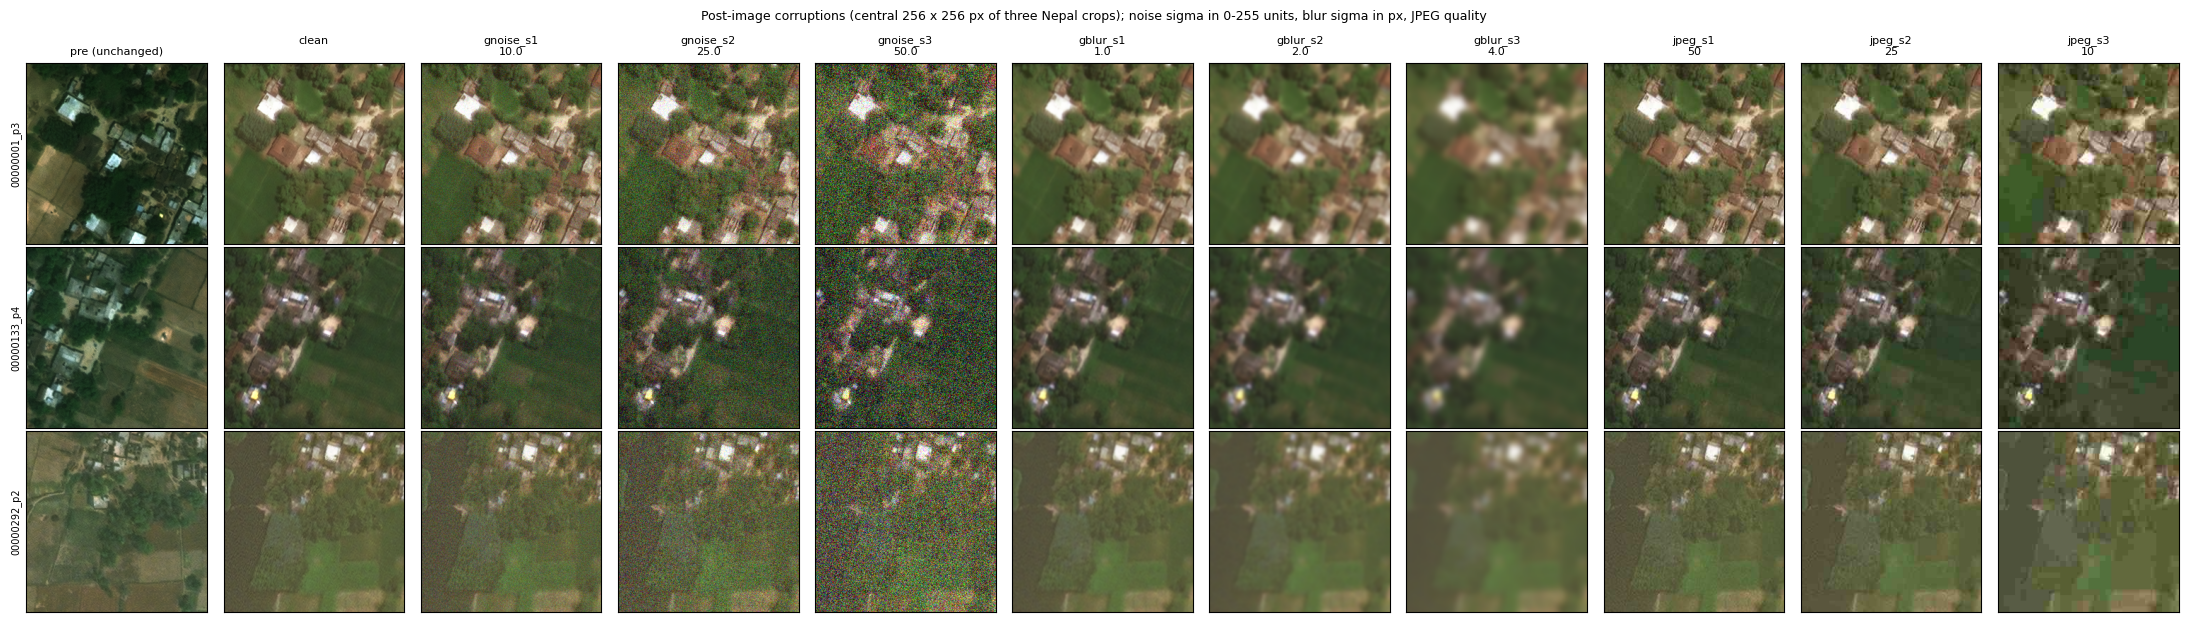

samples: ['nepal-flooding_00000001_p3', 'nepal-flooding_00000133_p4', 'nepal-flooding_00000292_p2', 'nepal-flooding_00000412_p3', 'nepal-flooding_00000510_p4', 'nepal-flooding_00000618_p4']


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
# Six crops chosen by a fixed rule: >= 5% building pixels, >= 99% valid, evenly spaced
CROP_DF = pd.read_csv(out("corruption", "manifest", "crop_manifest_nepal.csv"))
elig = CROP_DF[(CROP_DF.building_px >= 0.05 * 512 * 512) & (CROP_DF.valid_px >= 0.99 * 512 * 512)].reset_index(drop=True)
SAMPLES = list(elig.crop_id.iloc[np.linspace(0, len(elig) - 1, 6).round().astype(int)])
# Save the pre image and every corrupted post image of each sample (hash-checked)
rowmap = dict(zip(ORDER, TEST.rows))
for tid in SAMPLES:
    pre, post, mask, valid = load_crop(X, rowmap[tid])
    Image.fromarray(pre).save(out("corruption", "samples", f"{tid}__pre.png"))
    for cond in CONDITIONS:
        y = corruption.corrupt(post, cond, tid)
        assert corruption.sha256(y) == pd.read_csv(f"{HASH_DIR}/{cond}.csv").set_index("crop_id").loc[tid, "post_sha256"]
        Image.fromarray(y).save(out("corruption", "samples", f"{tid}__post__{cond}.png"))
# Figure: central 256 x 256 px of three samples under every condition
cols = ["pre (unchanged)"] + list(CONDITIONS)
f, ax = plt.subplots(3, len(cols), figsize=(2.0 * len(cols), 6.3))
for r, tid in enumerate(SAMPLES[:3]):
    pre, post, _, _ = load_crop(X, rowmap[tid])
    for k, cname in enumerate(cols):
        img = pre if k == 0 else corruption.corrupt(post, cname, tid)
        ax[r, k].imshow(img[128:384, 128:384]); ax[r, k].set_xticks([]); ax[r, k].set_yticks([])
        if r == 0:
            ax[r, k].set_title(cname if k == 0 else f"{cname}\n{CONDITIONS[cname][2] if CONDITIONS[cname][2] else ''}", fontsize=8)
    ax[r, 0].set_ylabel(tid.replace("nepal-flooding_", ""), fontsize=7)
f.suptitle("Post-image corruptions (central 256 x 256 px of three Nepal crops); noise sigma in 0-255 units, blur sigma in px, JPEG quality", fontsize=9)
f.tight_layout(); f.savefig(out("figures", "corruption_examples.png"), dpi=180, bbox_inches="tight"); plt.show()
print("samples:", SAMPLES)

## 13. Analysis
Per checkpoint and condition: all metrics (pixel and building level). Degradation against the checkpoint's own clean
pass: absolute and relative, with paired bootstrap 95% intervals over the 619 images (1,000 resamples). Per family:
mean and std over the 3 seeds, and a family-level paired bootstrap (same image resample for all seeds, seed-mean delta).
Primary families and the EXPLORATORY ablation are written to separate files.

In [ ]:
# All metrics for every checkpoint and condition
IL, MET = {}, []
for c in CKPTS:
    for cond in CONDITIONS:
        IL[(c["run"], cond)] = CA.image_level(dict(np.load(npz_path(c, cond))))
        m = CA.metrics_on(IL[(c["run"], cond)])
        t, sv, prm, unit = CONDITIONS[cond]
        MET.append({"group": c["group"], "family": c["family"], "run": c["run"], "seed": c["seed"], "evaluation_status": c["status"],
                    "condition": cond, "type": t, "severity": sv, "parameter": prm, "unit": unit, **m})
MET_DF = pd.DataFrame(MET)
# Absolute and relative change from each checkpoint's own clean pass
mkeys = [k for k in MET_DF.columns if k not in ("group", "family", "run", "seed", "evaluation_status", "condition", "type", "severity", "parameter", "unit")]
clean_ref = MET_DF[MET_DF.condition == "clean"].set_index("run")[mkeys]
for k in mkeys:
    MET_DF[f"{k}__clean"] = MET_DF.run.map(clean_ref[k])
    MET_DF[f"{k}__delta"] = MET_DF[k] - MET_DF[f"{k}__clean"]
    MET_DF[f"{k}__rel"] = MET_DF[f"{k}__delta"] / MET_DF[f"{k}__clean"]
# Primary families and the ablation are saved separately
PRIM, ABLM = MET_DF[MET_DF.group == "primary"], MET_DF[MET_DF.group == "EXPLORATORY"]
PRIM.to_csv(out("results", "corruption_metrics_per_checkpoint_primary.csv"), index=False)
ABLM.to_csv(out("results", "corruption_metrics_EXPLORATORY_ablation.csv"), index=False)

# per-class precision / recall / F1 (pixel: 5-class and damage-on-building-pixels)
LONG = []
for c in CKPTS:
    for cond in CONDITIONS:
        e = metrics_ext.extended(IL[(c["run"], cond)]["cms"].sum(0))
        for fam_key, fam_name, names in (("dmg", "damage (GT building px)", metrics_ext.DAMAGE_NAMES), ("px5", "5-class (all valid px)", metrics_ext.NAMES)):
            for n in names:
                LONG.append({"group": c["group"], "family": c["family"], "run": c["run"], "seed": c["seed"], "condition": cond,
                             "metric_family": fam_name, "class": n, **{k: e[f"{fam_key}_{n}_{k}"] for k in ("precision", "recall", "f1")}})
LONG_DF = pd.DataFrame(LONG)
LONG_DF[LONG_DF.group == "primary"].to_csv(out("results", "corruption_per_class_prf_primary.csv"), index=False)
LONG_DF[LONG_DF.group == "EXPLORATORY"].to_csv(out("results", "corruption_per_class_prf_EXPLORATORY_ablation.csv"), index=False)

# paired bootstrap: per checkpoint, then per family
t0 = time.time()
BOOT_CK, BOOT_FAM = [], []
for c in CKPTS:
    for cond in [k for k in CONDITIONS if k != "clean"]:
        b = CA.paired_delta_bootstrap([IL[(c["run"], "clean")]], [IL[(c["run"], cond)]], n_boot=1000)
        BOOT_CK += [{"group": c["group"], "family": c["family"], "run": c["run"], "condition": cond, "metric": k, **v} for k, v in b.items()]
fam_runs = {}
for c in CKPTS:
    fam_runs.setdefault((c["group"], c["family"]), []).append(c["run"])
for (grp, fam), runs in fam_runs.items():
    for cond in [k for k in CONDITIONS if k != "clean"]:
        b = CA.paired_delta_bootstrap([IL[(r, "clean")] for r in runs], [IL[(r, cond)] for r in runs], n_boot=1000)
        BOOT_FAM += [{"group": grp, "family": fam, "n_seeds": len(runs), "condition": cond, "metric": k, **v} for k, v in b.items()]
BOOT_CK_DF, BOOT_FAM_DF = pd.DataFrame(BOOT_CK), pd.DataFrame(BOOT_FAM)
for df, name in ((BOOT_CK_DF, "corruption_paired_bootstrap_per_checkpoint"), (BOOT_FAM_DF, "corruption_paired_bootstrap_per_family")):
    df[df.group == "primary"].to_csv(out("results", f"{name}_primary.csv"), index=False)
    df[df.group == "EXPLORATORY"].to_csv(out("results", f"{name}_EXPLORATORY_ablation.csv"), index=False)
print(f"bootstrap done in {time.time() - t0:.0f}s")

# family summary: mean and std over seeds of the metric, the delta and the relative delta, plus the family bootstrap CI
SUMK = ["xview2_pixel_score", "damage_macro_f1", "building_iou", "binary_miou", "miou", "loc_f1",
        "dmg_f1_no_damage", "dmg_f1_minor", "dmg_f1_major", "dmg_f1_destroyed", "xview2_building_score"]
rows = []
for (grp, fam), g in MET_DF.groupby(["group", "family"], sort=False):
    for cond, gc_ in g.groupby("condition", sort=False):
        r = {"group": grp, "family": fam, "n_seeds": len(gc_), "condition": cond, "type": gc_.type.iloc[0],
             "severity": gc_.severity.iloc[0], "parameter": gc_.parameter.iloc[0], "evaluation_status": gc_.evaluation_status.iloc[0]}
        for k in SUMK:
            r[f"{k}_mean"], r[f"{k}_std"] = gc_[k].mean(), gc_[k].std(ddof=1) if len(gc_) > 1 else np.nan
            r[f"{k}_delta_mean"], r[f"{k}_delta_std"] = gc_[f"{k}__delta"].mean(), gc_[f"{k}__delta"].std(ddof=1) if len(gc_) > 1 else np.nan
            r[f"{k}_rel_mean"], r[f"{k}_rel_std"] = gc_[f"{k}__rel"].mean(), gc_[f"{k}__rel"].std(ddof=1) if len(gc_) > 1 else np.nan
            bf = BOOT_FAM_DF[(BOOT_FAM_DF.family == fam) & (BOOT_FAM_DF.condition == cond) & (BOOT_FAM_DF.metric == k)]
            if len(bf):
                r[f"{k}_delta_ci95"] = f"[{bf.delta_lo.iloc[0]:.4f}, {bf.delta_hi.iloc[0]:.4f}]"
                r[f"{k}_rel_ci95"] = f"[{bf.rel_lo.iloc[0]:.4f}, {bf.rel_hi.iloc[0]:.4f}]"
        rows.append(r)
FAM_DF = pd.DataFrame(rows)
FAM_DF[FAM_DF.group == "primary"].to_csv(out("results", "corruption_family_summary_primary.csv"), index=False)
FAM_DF[FAM_DF.group == "EXPLORATORY"].to_csv(out("results", "corruption_summary_EXPLORATORY_ablation.csv"), index=False)

# consolidated long table, primary only (one row per checkpoint x condition x metric)
CONS = []
bk = BOOT_CK_DF.set_index(["run", "condition", "metric"])
for _, r in PRIM.iterrows():
    for k in SUMK:
        rec = {"family": r.family, "run": r.run, "seed": r.seed, "evaluation_status": r.evaluation_status, "condition": r.condition,
               "type": r.type, "severity": r.severity, "parameter": r.parameter, "metric": k, "value": r[k],
               "clean_value": r[f"{k}__clean"], "delta": r[f"{k}__delta"], "rel_delta": r[f"{k}__rel"]}
        if (r.run, r.condition, k) in bk.index:
            v = bk.loc[(r.run, r.condition, k)]; rec.update({"delta_ci95_lo": v.delta_lo, "delta_ci95_hi": v.delta_hi})
        CONS.append(rec)
pd.DataFrame(CONS).to_csv(out("results", "consolidated_results_primary.csv"), index=False)
# Print the family summaries
SHOWF = ["family", "condition", "xview2_pixel_score_mean", "xview2_pixel_score_std", "xview2_pixel_score_delta_mean",
         "xview2_pixel_score_rel_mean", "xview2_pixel_score_delta_ci95", "damage_macro_f1_mean", "damage_macro_f1_rel_mean",
         "building_iou_mean", "building_iou_rel_mean", "xview2_building_score_mean"]
print("PRIMARY families (mean over 3 seeds):"); print(FAM_DF[FAM_DF.group == "primary"][SHOWF].round(4).to_string(index=False))
print("\nEXPLORATORY ablation (1 seed; separate):"); print(FAM_DF[FAM_DF.group == "EXPLORATORY"][SHOWF].round(4).to_string(index=False))

bootstrap done in 239s
PRIMARY families (mean over 3 seeds):
                     family condition  xview2_pixel_score_mean  xview2_pixel_score_std  xview2_pixel_score_delta_mean  xview2_pixel_score_rel_mean xview2_pixel_score_delta_ci95  damage_macro_f1_mean  damage_macro_f1_rel_mean  building_iou_mean  building_iou_rel_mean  xview2_building_score_mean
M0 early fusion, Dice+focal     clean                   0.3356                  0.0367                         0.0000                       0.0000                           NaN                0.2732                    0.0000             0.4951                 0.0000                      0.3306
M0 early fusion, Dice+focal gnoise_s1                   0.3220                  0.0244                        -0.0135                      -0.0375            [-0.0203, -0.0048]                0.2385                   -0.1235             0.4411                -0.1090                      0.3155
M0 early fusion, Dice+focal gnoise_s2                 

## 14. Figures (primary families; the EXPLORATORY ablation in its own figure). Each figure's data is also saved as CSV.
Colours: validated categorical palette, fixed order per family, plus a distinct marker per family (palette contrast
warning: identity is never colour-only). Error bars: std over the 3 seeds.

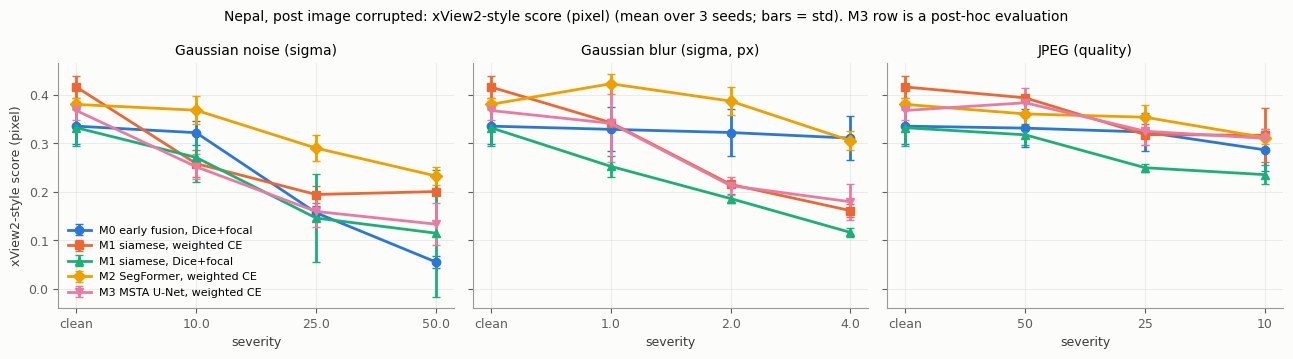

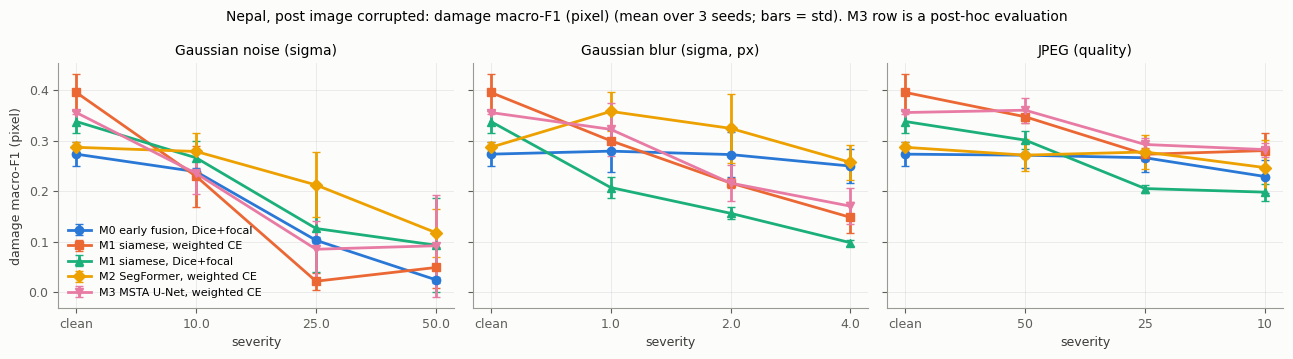

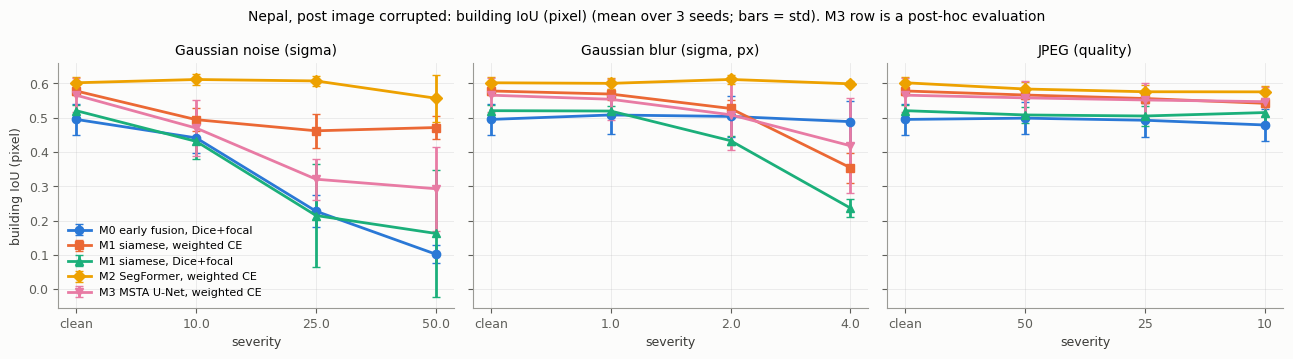

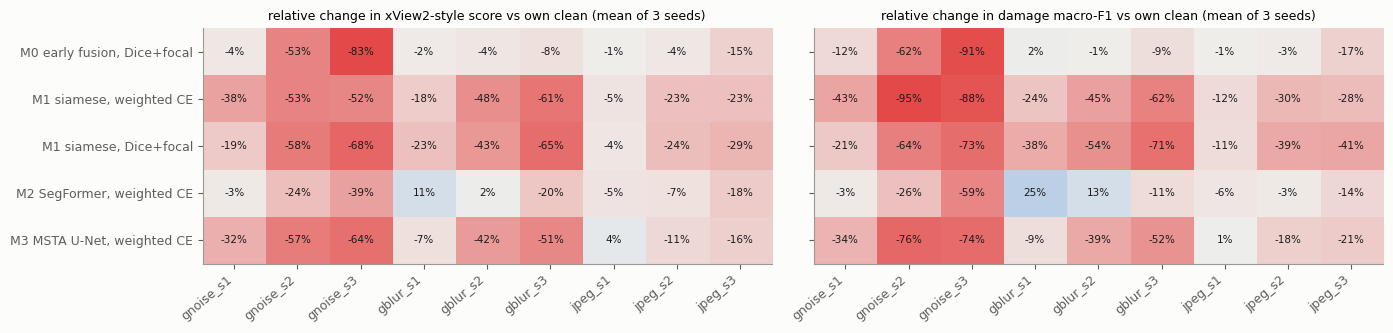

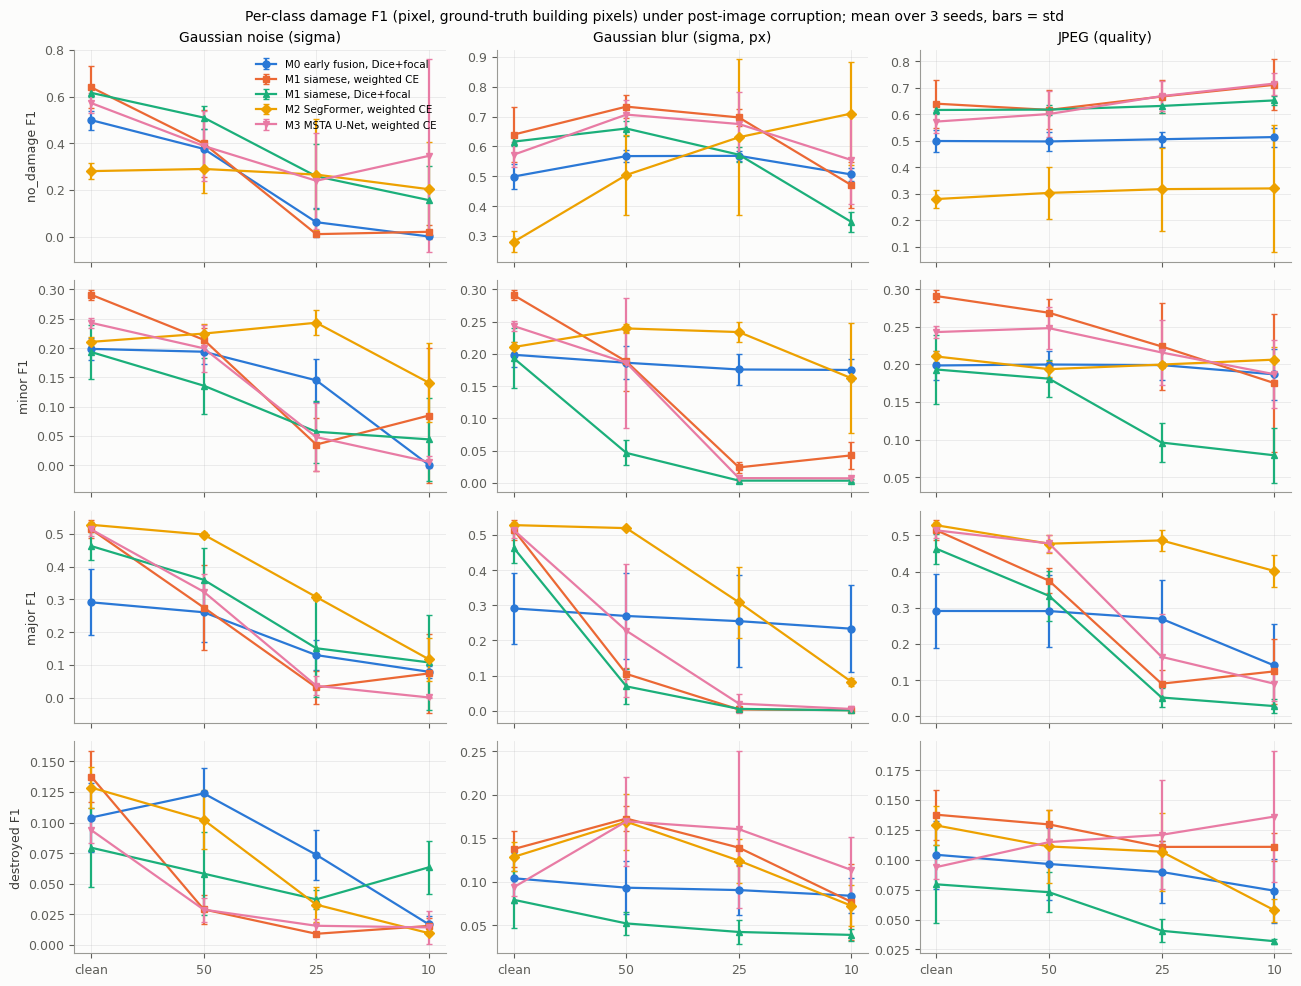

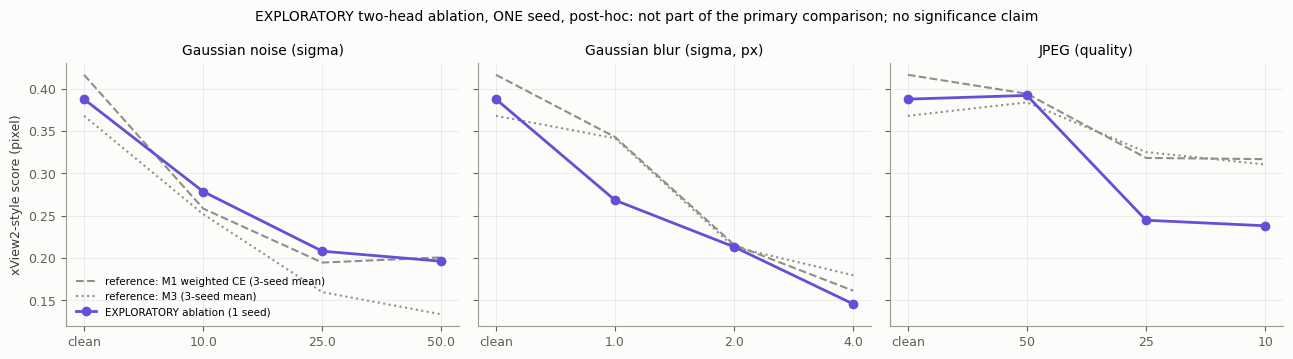

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
# Plot style
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "grid.linewidth": 0.6, "font.size": 9, "axes.edgecolor": "#9a9a95", "axes.labelcolor": "#3a3a37",
                     "xtick.color": "#5e5e59", "ytick.color": "#5e5e59", "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
# Fixed colour and marker per family
FAM_ORDER = list(FAMILIES)
COL = dict(zip(FAM_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
MRK = dict(zip(FAM_ORDER, ["o", "s", "^", "D", "v"]))
TYPES = [("gaussian_noise", "Gaussian noise (sigma)", "gnoise"), ("gaussian_blur", "Gaussian blur (sigma, px)", "gblur"),
         ("jpeg", "JPEG (quality)", "jpeg")]
P = FAM_DF[FAM_DF.group == "primary"]

# One family's values from clean to severity 3 for one corruption type
def series(df, fam, prefix, key):
    clean = df[(df.family == fam) & (df.condition == "clean")]
    sub = df[(df.family == fam) & (df.condition.str.startswith(prefix))].sort_values("severity")
    s = pd.concat([clean, sub])
    return s.severity.values, s[f"{key}_mean"].values, s[f"{key}_std"].values, s

# Three panels (noise, blur, JPEG): metric vs severity per family, bars = std over seeds; data also saved as CSV
def severity_figure(key, label, fname):
    f, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
    rows = []
    for a, (t, tl, pre) in zip(ax, TYPES):
        params = ["clean"] + [str(CONDITIONS[f"{pre}_s{k}"][2]) for k in (1, 2, 3)]
        for fam in FAM_ORDER:
            x, y, e, s = series(P, fam, pre, key)
            a.errorbar(x, y, yerr=e, color=COL[fam], marker=MRK[fam], ms=6, lw=2, capsize=3, label=fam)
            rows += [{"corruption": t, "family": fam, "severity": int(sv), "condition": cd, f"{key}_mean": m, f"{key}_std": sd}
                     for sv, cd, m, sd in zip(s.severity, s.condition, s[f"{key}_mean"], s[f"{key}_std"])]
        a.set_xticks([0, 1, 2, 3]); a.set_xticklabels(params); a.set_title(tl, fontsize=10); a.set_xlabel("severity")
    ax[0].set_ylabel(label)
    ax[0].legend(fontsize=8, frameon=False, loc="lower left")
    f.suptitle(f"Nepal, post image corrupted: {label} (mean over 3 seeds; bars = std). M3 row is a post-hoc evaluation", fontsize=10)
    f.tight_layout(); f.savefig(out("figures", fname), dpi=200, bbox_inches="tight"); plt.show()
    pd.DataFrame(rows).to_csv(out("figures", fname.replace(".png", "_data.csv")), index=False)

# Pixel score, damage macro-F1 and building IoU
severity_figure("xview2_pixel_score", "xView2-style score (pixel)", "corruption_xview2_score_vs_severity_primary.png")
severity_figure("damage_macro_f1", "damage macro-F1 (pixel)", "corruption_damage_macro_f1_vs_severity_primary.png")
severity_figure("building_iou", "building IoU (pixel)", "corruption_building_iou_vs_severity_primary.png")

# relative degradation heatmap (diverging: red = worse than own clean, grey = no change, blue = better)
CMAP = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
conds = [c for c in CONDITIONS if c != "clean"]
f, ax = plt.subplots(1, 2, figsize=(14, 3.4))
hm_rows = []
for a, (key, lab) in zip(ax, [("xview2_pixel_score", "xView2-style score"), ("damage_macro_f1", "damage macro-F1")]):
    Mx = np.array([[P[(P.family == fam) & (P.condition == c)][f"{key}_rel_mean"].iloc[0] for c in conds] for fam in FAM_ORDER])
    v = np.nanmax(np.abs(Mx))
    a.imshow(Mx, cmap=CMAP, vmin=-v, vmax=v, aspect="auto")
    for i in range(Mx.shape[0]):
        for j in range(Mx.shape[1]):
            a.text(j, i, f"{100 * Mx[i, j]:.0f}%", ha="center", va="center", fontsize=7.5, color="#1a1a19")
            hm_rows.append({"metric": key, "family": FAM_ORDER[i], "condition": conds[j], "rel_mean": Mx[i, j]})
    a.set_xticks(range(len(conds))); a.set_xticklabels(conds, rotation=40, ha="right")
    a.set_yticks(range(len(FAM_ORDER))); a.set_yticklabels(FAM_ORDER if a is ax[0] else []); a.grid(False)
    a.set_title(f"relative change in {lab} vs own clean (mean of 3 seeds)", fontsize=9)
f.tight_layout(); f.savefig(out("figures", "corruption_relative_degradation_heatmap_primary.png"), dpi=200, bbox_inches="tight"); plt.show()
pd.DataFrame(hm_rows).to_csv(out("figures", "corruption_relative_degradation_heatmap_primary_data.csv"), index=False)

# per-class damage F1: rows = damage class, columns = corruption type
f, ax = plt.subplots(4, 3, figsize=(13, 10), sharex=True)
pc_rows = []
for i, cls in enumerate(["no_damage", "minor", "major", "destroyed"]):
    for j, (t, tl, pre) in enumerate(TYPES):
        a = ax[i, j]
        for fam in FAM_ORDER:
            x, y, e, s = series(P, fam, pre, f"dmg_f1_{cls}")
            a.errorbar(x, y, yerr=e, color=COL[fam], marker=MRK[fam], ms=5, lw=1.6, capsize=2, label=fam)
            pc_rows += [{"class": cls, "corruption": t, "family": fam, "severity": int(sv), "f1_mean": m, "f1_std": sd}
                        for sv, m, sd in zip(s.severity, s[f"dmg_f1_{cls}_mean"], s[f"dmg_f1_{cls}_std"])]
        a.set_xticks([0, 1, 2, 3]); a.set_xticklabels(["clean"] + [str(CONDITIONS[f"{pre}_s{k}"][2]) for k in (1, 2, 3)])
        if i == 0: a.set_title(tl, fontsize=10)
        if j == 0: a.set_ylabel(f"{cls} F1")
ax[0, 0].legend(fontsize=7.5, frameon=False)
f.suptitle("Per-class damage F1 (pixel, ground-truth building pixels) under post-image corruption; mean over 3 seeds, bars = std", fontsize=10)
f.tight_layout(); f.savefig(out("figures", "corruption_per_class_f1_primary.png"), dpi=200, bbox_inches="tight"); plt.show()
pd.DataFrame(pc_rows).to_csv(out("figures", "corruption_per_class_f1_primary_data.csv"), index=False)

# EXPLORATORY ablation: its own figure; family means of M1 CE and M3 shown only as grey reference lines
A = FAM_DF[FAM_DF.group == "EXPLORATORY"]
fam_a = A.family.iloc[0]
f, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
ab_rows = []
for a, (t, tl, pre) in zip(ax, TYPES):
    for fam, ls, lab in (("M1 siamese, weighted CE", "--", "reference: M1 weighted CE (3-seed mean)"),
                         ("M3 MSTA U-Net, weighted CE", ":", "reference: M3 (3-seed mean)")):
        x, y, _, _ = series(P, fam, pre, "xview2_pixel_score"); a.plot(x, y, ls, color="#8f8f89", lw=1.5, label=lab)
    x, y, _, s = series(A, fam_a, pre, "xview2_pixel_score")
    a.plot(x, y, color="#6250d6", marker="o", ms=6, lw=2, label="EXPLORATORY ablation (1 seed)")
    ab_rows += [{"corruption": t, "severity": int(sv), "xview2_pixel_score": m} for sv, m in zip(s.severity, s.xview2_pixel_score_mean)]
    a.set_xticks([0, 1, 2, 3]); a.set_xticklabels(["clean"] + [str(CONDITIONS[f"{pre}_s{k}"][2]) for k in (1, 2, 3)]); a.set_title(tl, fontsize=10)
ax[0].set_ylabel("xView2-style score (pixel)"); ax[0].legend(fontsize=7.5, frameon=False, loc="lower left")
f.suptitle("EXPLORATORY two-head ablation, ONE seed, post-hoc: not part of the primary comparison; no significance claim", fontsize=10)
f.tight_layout(); f.savefig(out("figures", "corruption_EXPLORATORY_ablation.png"), dpi=200, bbox_inches="tight"); plt.show()
pd.DataFrame(ab_rows).to_csv(out("figures", "corruption_EXPLORATORY_ablation_data.csv"), index=False)

## 15. Timing, compute, preservation check and summary

In [ ]:
# Timing of every full condition pass
TALL = []
for fn in sorted(os.listdir(out("corruption", "timing"))):
    t = json.load(open(out("corruption", "timing", fn)))
    TALL.append({"file": fn, **{k: t.get(k) for k in ("crops", "images", "models", "wall", "gpu", "data_wait", "stitch",
                                                         "score_backpressure", "score_tail", "score_worker_cpu", "finished")}})
T_DF = pd.DataFrame(TALL)
T_DF.to_csv(out("results", "corruption_timing.csv"), index=False)
# GPU seconds per checkpoint, summed over all conditions
gpm = {}
for fn in sorted(os.listdir(out("corruption", "timing"))):
    for k, v in json.load(open(out("corruption", "timing", fn))).get("gpu_per_model", {}).items():
        gpm[k] = gpm.get(k, 0) + v
# Session length and an estimate of compute units (not read from Colab)
SESSION["session_end"] = datetime.datetime.now().isoformat(timespec="seconds")
sess_h = (datetime.datetime.fromisoformat(SESSION["session_end"]) - datetime.datetime.fromisoformat(SESSION["session_start"])).total_seconds() / 3600
# Nothing outside m3_experiments/ may have changed
AFTER = snapshot()
ch = {"added": sorted(set(AFTER) - set(BEFORE)), "removed": sorted(set(BEFORE) - set(AFTER)),
      "changed": sorted(k for k in set(BEFORE) & set(AFTER) if BEFORE[k] != AFTER[k])}
PRES = "NOTHING OUTSIDE m3_experiments CHANGED" if not any(ch.values()) else f"DIFFERENCES: {ch}"
fp = FAM_DF[FAM_DF.group == "primary"]
# Summary of everything above, saved and printed
SUMMARY = {
  "session": {**SESSION, "this_session_hours": round(sess_h, 2),
              "estimated_units_this_session (assumes ~4.8 units/h on L4; check Colab's Resources panel)": round(4.8 * sess_h, 1)},
  "evaluation_status": {"frozen 18 Nov comparison set (reproduced here)": ST_FROZEN, "M3": ST_M3, "EXPLORATORY ablation": ST_ABL},
  "checkpoints_sha_verified": bool(CK_DF.sha256_matches_earlier_verification.all()),
  "preprocessing_equivalence": PREP_EQ,
  "gpu_confusion_exact_check": CONF_CHECK,
  "clean_reproduction_gated": REPRO_DF[GATE_COLS].round(6).to_dict(orient="records"),
  "clean_reproduction_building_level_reported": REPRO_DF[BLD_COLS + ["differing_images (true classes affected)"]].round(5).to_dict(orient="records"),
  "input_hashes": HASH_SUMMARY,
  "timing_benchmark_64_crops": TB.round(2).to_dict(orient="records"),
  "timing_full_conditions": T_DF.round(1).to_dict(orient="records"),
  "timing_totals_h": {"wall": round(T_DF.wall.sum() / 3600, 3), "gpu_inference": round(T_DF.gpu.sum() / 3600, 3),
                      "cpu_building_scoring_worker_time": round(T_DF.score_worker_cpu.sum() / 3600, 3),
                      "data_wait": round(T_DF.data_wait.sum() / 3600, 3), "scoring_backpressure": round(T_DF.score_backpressure.sum() / 3600, 3)},
  "gpu_seconds_per_checkpoint": {k: round(v, 1) for k, v in gpm.items()},
  "primary_family_summary": fp[SHOWF + ["dmg_f1_destroyed_mean", "dmg_f1_destroyed_rel_mean", "xview2_building_score_rel_mean"]].round(4).to_dict(orient="records"),
  "EXPLORATORY_ablation_summary": FAM_DF[FAM_DF.group == "EXPLORATORY"][SHOWF].round(4).to_dict(orient="records"),
  "preservation": PRES}
jdump(SUMMARY, out("results", f"stage5_summary_{datetime.datetime.now():%Y%m%d_%H%M}.json"))
print(json.dumps(SUMMARY, indent=1, default=str))

{
 "session": {
  "session_start": "2026-11-20T21:54:02",
  "gpu": "NVIDIA L4",
  "session_end": "2026-11-20T23:08:58",
  "this_session_hours": 1.25,
  "estimated_units_this_session (assumes ~4.8 units/h on L4; check Colab's Resources panel)": 6.0
 },
 "evaluation_status": {
  "frozen 18 Nov comparison set (reproduced here)": "18 Nov frozen Nepal comparison set (best.pt chosen on Florence before any Nepal result); clean pass here = reproduction",
  "M3": "post-hoc: designed and trained 20 Nov after the 18 Nov Nepal results were known; selected on Florence only; first Nepal evaluation; NOT a blind test",
  "EXPLORATORY ablation": "EXPLORATORY ablation, one seed, post-hoc (same caveat as M3); never in the primary comparison"
 },
 "checkpoints_sha_verified": true,
 "preprocessing_equivalence": {
  "tensors_identical_16_crops": true,
  "crop_order_identical": true,
  "gpu_confusion_equals_metrics_confusion": true,
  "argmax_rule": "model(pre, post).argmax(1) under autocast, batch 8, sorted

## End of notebook
Releases the Colab runtime so it stops using compute units.

In [ ]:
# Release the Colab runtime
from google.colab import runtime
runtime.unassign()